# Visualización meteorológica con Matplotlib

<div style="height: 4px; background-color: #4C78A8; border-radius: 2px; margin: 0.8em 0 1.2em;"></div>

<div style="padding: 0.8em 1em; margin: 0.8em 0 1.2em; border-left: 4px solid #4C78A8; background-color: rgba(76,120,168,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.45em 0;">Una <strong>visualización</strong> convierte datos en una representación que podemos interpretar. Una curva permite seguir la evolución de la temperatura, unas barras ayudan a comparar acumulados de lluvia y un campo de colores muestra cómo varía una magnitud en el espacio.</p>
</div>

**Matplotlib** es una biblioteca de Python para crear gráficos y controlar sus elementos, desde las líneas y los puntos hasta los títulos, las escalas y las leyendas. Trabajaremos con series temporales, diagramas de dispersión, distribuciones y campos bidimensionales de interés meteorológico.

Los ejemplos utilizan **datos sintéticos**, generados con fórmulas sencillas y números aleatorios reproducibles. No corresponden a observaciones de una estación ni permiten identificar episodios meteorológicos reales.

Los objetivos principales son:

- Comprender cómo se organizan las figuras y cómo se dibujan datos con Matplotlib.
- Ajustar ejes, fechas, etiquetas, leyendas y estilos para facilitar la lectura.
- Elegir representaciones adecuadas para temperatura, humedad, viento y precipitación.
- Preparar figuras reproducibles y exportarlas para informes, publicaciones o docencia.

In [2]:
import sys
!{sys.executable} -m pip install matplotlib

  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp314-cp314-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl (9.5 MB)
Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl (240 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp314-cp314-win_amd64.whl (2.5 MB)
Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl (72 kB)
Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl (7.3 MB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)

   ---------------------------------------- 0/7 [pyparsing]
   -

## 1. Preparación del entorno y de los datos

Utilizaremos **NumPy** para construir las series y **Matplotlib** para representarlas. En los ejercicios también aparecerá **pandas**, que permite generar secuencias de fechas. El nombre `np` abrevia NumPy y `plt` identifica el módulo `matplotlib.pyplot`. Estos nombres son convenciones habituales, no palabras reservadas de Python.

La primera celda reúne las importaciones, unos ajustes visuales comunes y las series que emplearán los ejemplos. No es necesario memorizar todas las fórmulas para aprender a dibujar los gráficos. Lo importante es reconocer qué contiene cada array y en qué unidades se expresa.

| Nombre | Contenido | Unidad o tipo |
| --- | --- | --- |
| `fechas` | 60 fechas consecutivas, del 1 de junio al 30 de julio de 2024 | `datetime64[D]` |
| `T` | Temperatura diaria sintética | °C |
| `HR` | Humedad relativa sintética | % |
| `u`, `v` | Componentes del viento hacia el este y hacia el norte | m·s⁻¹ |
| `U` | Módulo del viento, calculado a partir de `u` y `v` | m·s⁻¹ |
| `P` | Precipitación acumulada durante cada día | mm |

<div style="padding: 0.8em 1em; margin: 0.8em 0 1.2em; border-left: 4px solid #59A14F; background-color: rgba(89,161,79,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.45em 0;">Una <strong>semilla</strong> fija permite repetir una secuencia de números pseudoaleatorios. Aquí sirve para que los gráficos muestren los mismos datos al repetir la generación. Los límites aplicados a la humedad forman parte de la simulación y no constituyen un procedimiento de control de calidad.</p>
</div>

Los parámetros de `plt.rcParams` establecen valores por defecto para las figuras creadas después. Podemos sobrescribirlos en un gráfico concreto, por ejemplo mediante `figsize` o `linewidth`. Los ejemplos de cajas utilizan `tick_labels`, disponible desde Matplotlib 3.9.

<p style="font-size: 0.9em; margin: 1em 0 0.3em;"><a href="https://matplotlib.org/stable/users/explain/customizing.html">Configuración de Matplotlib</a> · <a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.boxplot.html">Parámetros de boxplot</a></p>

In [3]:
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Estos valores por defecto se aplican a las figuras creadas después.
plt.rcParams.update({
    "figure.figsize": (7.0, 4.0),
    "figure.dpi": 120,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,
    "axes.axisbelow": True,  # La cuadrícula queda detrás de líneas y marcadores.
})

# Reiniciar el generador con la misma semilla reproduce estas series.
rng = np.random.default_rng(38)
n_dias = 60
fecha_inicio = np.datetime64("2024-06-01")
fechas = fecha_inicio + np.arange(n_dias).astype("timedelta64[D]")
d = np.arange(n_dias)  # Días transcurridos desde el inicio, de 0 a 59.

# Temperatura en °C. La oscilación anual solo aporta un fondo suave a estos 60 días.
# La fase sitúa un cruce del seno por cero, no su máximo.
T_media = 23.0
A_temp = 6.0
fase_temp = 30.0
ruido_T = rng.normal(loc=0.0, scale=1.2, size=n_dias)  # scale es la desviación estándar.
T = T_media + A_temp * np.sin(2 * np.pi * (d - fase_temp) / 365) + ruido_T

# Humedad relativa en %. El recorte es una decisión de la simulación.
HR_media = 65.0
A_hr = 10.0
fase_hr = 15.0
ruido_HR = rng.normal(loc=0.0, scale=3.0, size=n_dias)
HR = HR_media - A_hr * np.sin(2 * np.pi * (d - fase_hr) / 365) + ruido_HR
HR = np.clip(HR, 20.0, 100.0)

# Componentes hacia el este (u) y el norte (v), en m/s.
# Los periodos de 14 y 10 días se eligen solo para construir el ejemplo.
u = 3.0 + 1.5 * np.sin(2 * np.pi * d / 14) + rng.normal(0, 0.7, n_dias)
v = 1.0 + 1.0 * np.cos(2 * np.pi * d / 10) + rng.normal(0, 0.7, n_dias)
U = np.hypot(u, v)  # Equivale a sqrt(u**2 + v**2).

# Precipitación acumulada en cada día, en mm. Los días secos conservan el cero.
prob_lluvia = 0.35
llueve = rng.random(n_dias) < prob_lluvia
P = np.zeros(n_dias, dtype=float)
P[llueve] = rng.gamma(shape=1.8, scale=4.0, size=llueve.sum())
# La distribución gamma utilizada tiene una media de 1.8 * 4 = 7.2 mm en días lluviosos.

carpeta_figuras = Path("figuras_matplotlib")

print(f"NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")
print(f"Periodo de {n_dias} días, del {fechas[0]} al {fechas[-1]}")
print(f"T (°C) — mínimo {T.min():.1f}, máximo {T.max():.1f}, media {T.mean():.1f}")
print(f"HR (%) — mínimo {HR.min():.0f}, máximo {HR.max():.0f}, media {HR.mean():.0f}")
print(f"U (m/s) — mínimo {U.min():.1f}, máximo {U.max():.1f}, media {U.mean():.1f}")
print(f"Precipitación — {P.sum():.1f} mm en el periodo y {llueve.sum()} días con lluvia")

NumPy 2.5.2 | Matplotlib 3.11.2
Periodo de 60 días, del 2024-06-01 al 2024-07-30
T (°C) — mínimo 19.2, máximo 27.5, media 23.2
HR (%) — mínimo 53, máximo 72, media 62
U (m/s) — mínimo 0.9, máximo 5.4, media 3.3
Precipitación — 196.9 mm en el periodo y 21 días con lluvia


## 2. `pyplot` y API orientada a objetos

Una **API** es el conjunto de funciones y métodos con los que utilizamos una biblioteca. Matplotlib permite trabajar con dos enfoques que construyen los mismos tipos de objetos, aunque difieren en la forma de referirnos a ellos.

Con la interfaz **implícita** de `pyplot`, una llamada como `plt.plot(fechas, T)` dibuja sobre el panel activo. Es una forma cómoda de explorar datos con pocas instrucciones. Con la interfaz **orientada a objetos**, conservamos una referencia al panel y escribimos `ax.plot(fechas, T)`. Así indicamos de forma explícita dónde debe aparecer la curva.

<div style="padding: 0.8em 1em; margin: 0.8em 0 1.2em; border-left: 4px solid #4C78A8; background-color: rgba(76,120,168,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.45em 0;">La <strong>figura</strong>, representada por un objeto <code>Figure</code>, es el lienzo completo. Un objeto <code>Axes</code> es un <strong>panel de representación</strong> dentro de ese lienzo. Cada panel contiene sus propios ejes, datos, etiquetas y anotaciones. Una figura puede tener un solo panel o reunir varios.</p>
</div>

**`Axes` no equivale a un eje individual.** Aunque su nombre pueda resultar confuso, designa el panel completo. Sus objetos `XAxis` y `YAxis` gestionan los ejes horizontal y vertical. Las líneas, los textos y otros elementos que se dibujan pertenecen a la familia de objetos llamados *artistas* en Matplotlib.

La instrucción `fig, ax = plt.subplots()` crea una figura con un panel y guarda ambos objetos en dos variables. Después, `ax.set_ylabel("Temperatura (°C)")` modifica ese panel, mientras que `fig.savefig(...)` guarda la figura que tenemos en `fig`.

| Operación | Interfaz implícita | Interfaz explícita |
| --- | --- | --- |
| Dibujar una línea | `plt.plot(x, y)` | `ax.plot(x, y)` |
| Etiquetar el eje vertical | `plt.ylabel("T (°C)")` | `ax.set_ylabel("T (°C)")` |
| Añadir un título al panel | `plt.title("Temperatura")` | `ax.set_title("Temperatura")` |
| Guardar la figura | `plt.savefig("figura.png")` | `fig.savefig("figura.png")` |

Ambas formas son útiles. La interfaz explícita facilita especialmente el trabajo con varios paneles, escalas distintas o barras de color, porque permite ver qué objeto modifica cada instrucción. Por ejemplo, `axes[0, 1]` selecciona el panel de la primera fila y la segunda columna de una rejilla bidimensional.

<div style="padding: 0.8em 1em; margin: 0.8em 0 1.2em; border-left: 4px solid #59A14F; background-color: rgba(89,161,79,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.45em 0;"><strong>Idea clave.</strong> Usar <code>plt.subplots()</code> no contradice el enfoque orientado a objetos. Seguimos utilizando <code>pyplot</code> para crear la figura, pero dibujamos y ajustamos su contenido mediante <code>fig</code> y <code>ax</code>.</p>
</div>

Los dos primeros ejemplos representan la misma temperatura con cada interfaz. Después utilizaremos varios paneles y guardaremos una figura en un archivo.

<p style="font-size: 0.9em; margin: 1em 0 0.3em;"><a href="https://matplotlib.org/stable/users/explain/figure/api_interfaces.html">Interfaces de Matplotlib</a></p>

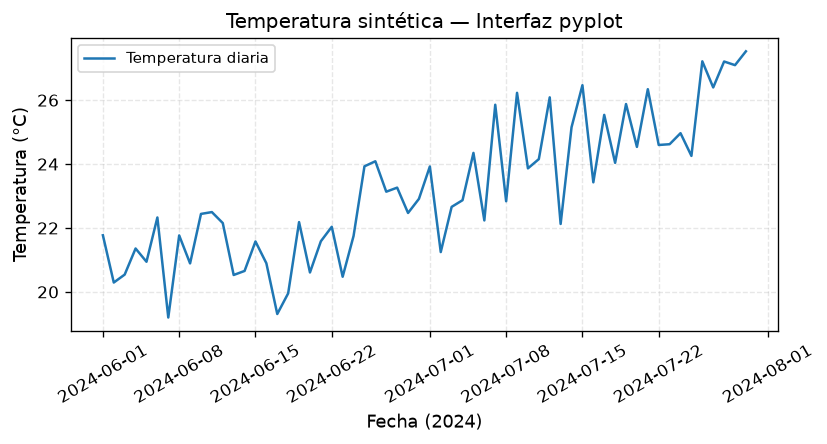

In [8]:
# 2.1 Interfaz implícita de pyplot.
# Las funciones actúan sobre la figura y el panel activos.
plt.figure(figsize=(7, 3.8), dpi=120)
plt.plot(fechas, T, linewidth=1.5, label="Temperatura diaria")
plt.title("Temperatura sintética — Interfaz pyplot")
plt.xlabel("Fecha (2024)")
plt.ylabel("Temperatura (°C)")
plt.xticks(rotation=30)
plt.grid(True, linestyle="--", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

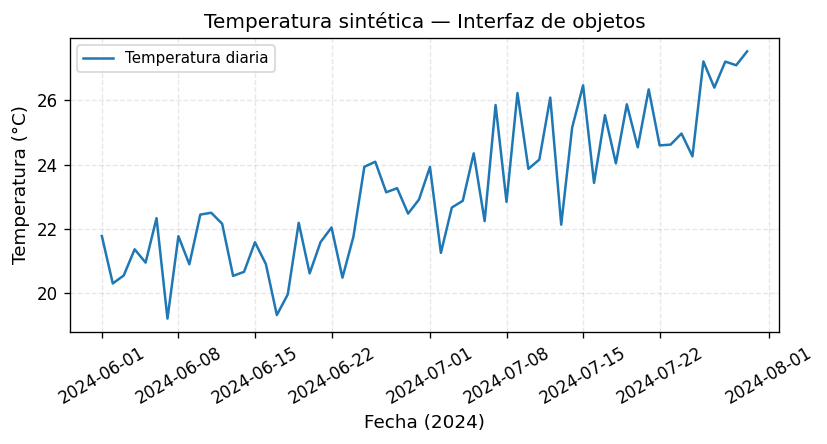

In [3]:
# 2.2 Interfaz explícita. fig es el lienzo y ax es el panel.
fig, ax = plt.subplots(figsize=(7, 3.8), dpi=120)
ax.plot(fechas, T, linewidth=1.5, label="Temperatura diaria")
ax.set_title("Temperatura sintética — Interfaz de objetos")
ax.set_xlabel("Fecha (2024)")
ax.set_ylabel("Temperatura (°C)")
ax.tick_params(axis="x", labelrotation=30)
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

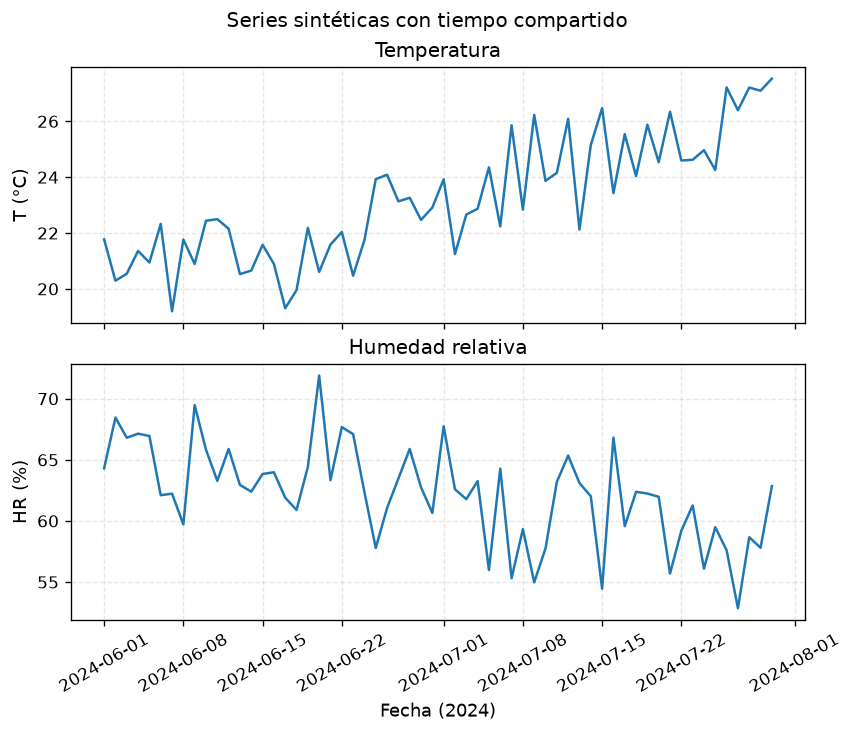

In [9]:
# 2.3 Dos paneles con el mismo eje temporal y escalas verticales independientes.
fig, axes = plt.subplots(2, 1, figsize=(7, 6), sharex=True, layout="constrained")
ax1, ax2 = axes  # axes contiene dos objetos Axes, accesibles también por índice.

ax1.plot(fechas, T, linewidth=1.5)
ax1.set_title("Temperatura")
ax1.set_ylabel("T (°C)")
ax1.grid(True, linestyle="--", alpha=0.3)

ax2.plot(fechas, HR, linewidth=1.5)
ax2.set_title("Humedad relativa")
ax2.set_ylabel("HR (%)")
ax2.set_xlabel("Fecha (2024)")
ax2.tick_params(axis="x", labelrotation=30)
ax2.grid(True, linestyle="--", alpha=0.3)

fig.suptitle("Series sintéticas con tiempo compartido")
plt.show()

Figura guardada en figuras_matplotlib\fig_serie_precipitacion.png


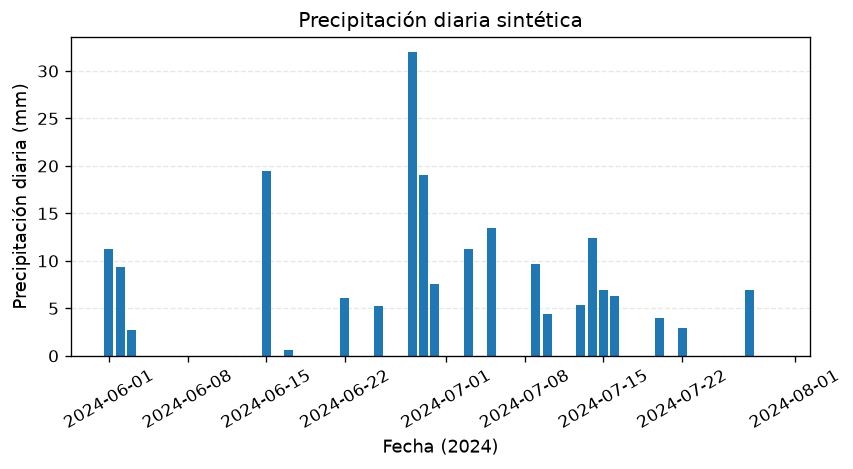

In [10]:
# 2.4 Guardar una figura. Las barras representan acumulados durante días separados.
fig, ax = plt.subplots(figsize=(7, 3.8), layout="constrained")
ax.bar(fechas, P, width=0.8)
ax.set_title("Precipitación diaria sintética")
ax.set_xlabel("Fecha (2024)")
ax.set_ylabel("Precipitación diaria (mm)")
ax.tick_params(axis="x", labelrotation=30)
ax.grid(True, axis="y", linestyle="--", alpha=0.3)

# La carpeta se crea si no existe. El mismo nombre de archivo reemplaza la exportación anterior.
carpeta_figuras.mkdir(exist_ok=True)
ruta_precipitacion = carpeta_figuras / "fig_serie_precipitacion.png"
fig.savefig(ruta_precipitacion, dpi=200, bbox_inches="tight")
print(f"Figura guardada en {ruta_precipitacion}")
plt.show()

## 3. Figuras, ejes y disposición de los paneles

El **diseño de una figura**, también llamado *layout*, distribuye el espacio entre paneles, títulos, etiquetas y leyendas. Una composición adecuada permite comparar los datos sin que estos elementos se superpongan.

**Creación y tamaño de las figuras**

`plt.subplots()` devuelve una figura y sus paneles. Con la configuración habitual, un solo panel se recibe como un objeto `Axes`; una fila o una columna de varios paneles produce un array de una dimensión, y una rejilla con varias filas y columnas produce un array de dos dimensiones.

```python
fig, ax = plt.subplots()                    # Un panel.
fig, axes = plt.subplots(nrows=2, ncols=2)   # Cuatro paneles; axes[0, 1] es el superior derecho.
```

El argumento `figsize=(ancho, alto)` expresa el tamaño en **pulgadas**, y `dpi` indica los puntos por pulgada usados al generar una imagen rasterizada. Una figura de 6 × 4 pulgadas a 150 dpi tiene un lienzo de 900 × 600 píxeles antes de cualquier recorte. Una pulgada equivale a 2,54 cm. El tamaño con el que se ve en pantalla puede variar según el navegador y la configuración de Jupyter.

```python
fig, ax = plt.subplots(figsize=(6, 4), dpi=150)
```

**Paneles y escalas compartidas**

| Parámetro | Función |
| --- | --- |
| `nrows`, `ncols` | Número de filas y columnas. |
| `sharex=True` | Comparte el eje horizontal entre paneles. |
| `sharey=True` | Comparte el eje vertical entre paneles. |
| `sharex="col"`, `sharey="row"` | Comparte el eje solo por columnas o por filas. |
| `gridspec_kw={"height_ratios": [3, 1]}` | Asigna al panel superior tres veces la altura del inferior. |

<div style="padding: 0.8em 1em; margin: 0.8em 0 1.2em; border-left: 4px solid #B88632; background-color: rgba(184,134,50,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.45em 0;"><strong>Comparaciones coherentes.</strong> Compartir el tiempo resulta útil para temperatura, humedad y precipitación medidas en las mismas fechas. En cambio, sus escalas verticales deben mantenerse separadas porque representan magnitudes y unidades diferentes. Compartir el eje vertical es apropiado, por ejemplo, al comparar dos series de temperatura.</p>
</div>

`ax.twinx()` crea un segundo panel superpuesto que comparte el tiempo, pero tiene su propia escala vertical. Permite combinar temperatura y precipitación con sus unidades respectivas. Sus alturas y cruces visuales no son comparables entre sí; para una lectura menos ambigua, a menudo conviene mantener dos paneles separados.

**Ajuste automático y ajuste manual**

Podemos crear la figura con `layout="constrained"` para que Matplotlib ajuste el espacio mientras la dibuja. La forma `constrained_layout=True`, presente en otros ejemplos y materiales, activa el mismo tipo de ajuste. Otra posibilidad es llamar a `fig.tight_layout()` una vez añadidos los elementos. Son alternativas y no conviene mezclarlas.

```python
fig, axes = plt.subplots(2, 2, figsize=(8, 6), layout="constrained")
```

Para controlar los márgenes manualmente, utilizamos `fig.subplots_adjust()` en una figura sin ajuste automático activo. `left`, `right`, `bottom` y `top` son posiciones relativas entre 0 y 1. `wspace` y `hspace` regulan la separación horizontal y vertical entre paneles, en relación con su tamaño.

```python
fig, axes = plt.subplots(2, 2, figsize=(8, 6), layout=None)
fig.subplots_adjust(left=0.10, right=0.95, bottom=0.12, top=0.90,
                    wspace=0.35, hspace=0.40)
```

`fig.autofmt_xdate()` rota y alinea las etiquetas de fecha, y también puede modificar el margen inferior. Cuando usamos `layout="constrained"`, resulta más sencillo ajustar la rotación mediante `ax.tick_params(axis="x", labelrotation=30)` y dejar los márgenes al gestor automático. La rotación no cambia el formato de las fechas, que veremos en el apartado 5.

**Títulos y composiciones desiguales**

`ax.set_title()` añade el título de un panel y `fig.suptitle()` coloca un **título global**, no un subtítulo. Podemos incorporar una nota con `fig.text(x, y, texto)`, donde las coordenadas se refieren por defecto a la figura completa. Los valores `(0, 0)` y `(1, 1)` corresponden a las esquinas inferior izquierda y superior derecha.

```python
fig, axes = plt.subplots(
    2, 1, figsize=(7, 6),
    gridspec_kw={"height_ratios": [3, 1]},
    layout="constrained",
)
fig.suptitle("Temperatura y precipitación sintéticas")
```

**Exportación**

`fig.savefig()` guarda la figura referenciada por `fig`, aunque no sea la figura activa de `pyplot`. Guardamos antes de `plt.show()` para que el comportamiento sea claro también fuera del notebook.

```python
fig.savefig("figura.png", dpi=300, bbox_inches="tight")
```

`bbox_inches="tight"` adapta el recorte al contenido y puede cambiar las dimensiones finales en píxeles. PNG almacena una imagen rasterizada. SVG y PDF pueden conservar líneas y textos como elementos vectoriales, aunque las imágenes de `imshow` siguen siendo rasterizadas y una malla muy grande puede generar archivos vectoriales pesados. El formato debe elegirse según el uso y las indicaciones de la publicación.

Las dos exportaciones de los ejemplos crean archivos PNG en `figuras_matplotlib`, dentro del directorio de trabajo. Guardar de nuevo con el mismo nombre reemplaza ese archivo.

<p style="font-size: 0.9em; margin: 1em 0 0.3em;"><a href="https://matplotlib.org/stable/users/explain/axes/constrainedlayout_guide.html">Disposición automática</a> · <a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.savefig.html">Exportación de figuras</a></p>

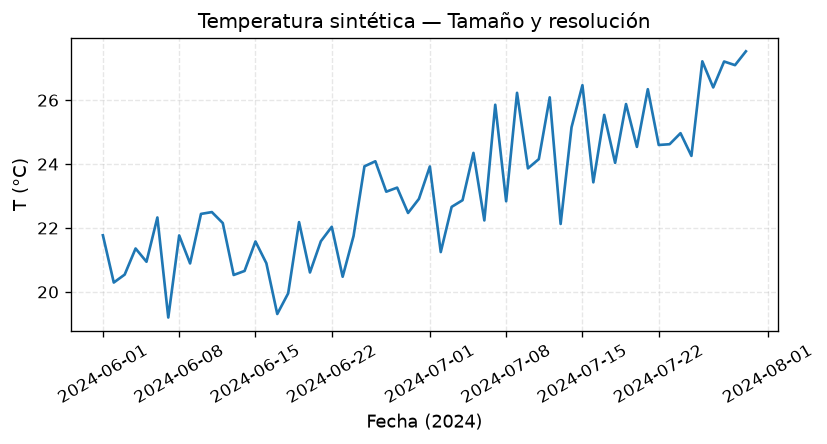

In [11]:
# 3.1 Tamaño físico y resolución del lienzo.
fig, ax = plt.subplots(figsize=(7, 3.8), dpi=120)
ax.plot(fechas, T, linewidth=1.6)
ax.set_title("Temperatura sintética — Tamaño y resolución")
ax.set_xlabel("Fecha (2024)")
ax.set_ylabel("T (°C)")
ax.tick_params(axis="x", labelrotation=30)
ax.grid(True, linestyle="--", alpha=0.3)

# Esta alternativa calcula los márgenes después de añadir los elementos.
fig.tight_layout()
plt.show()

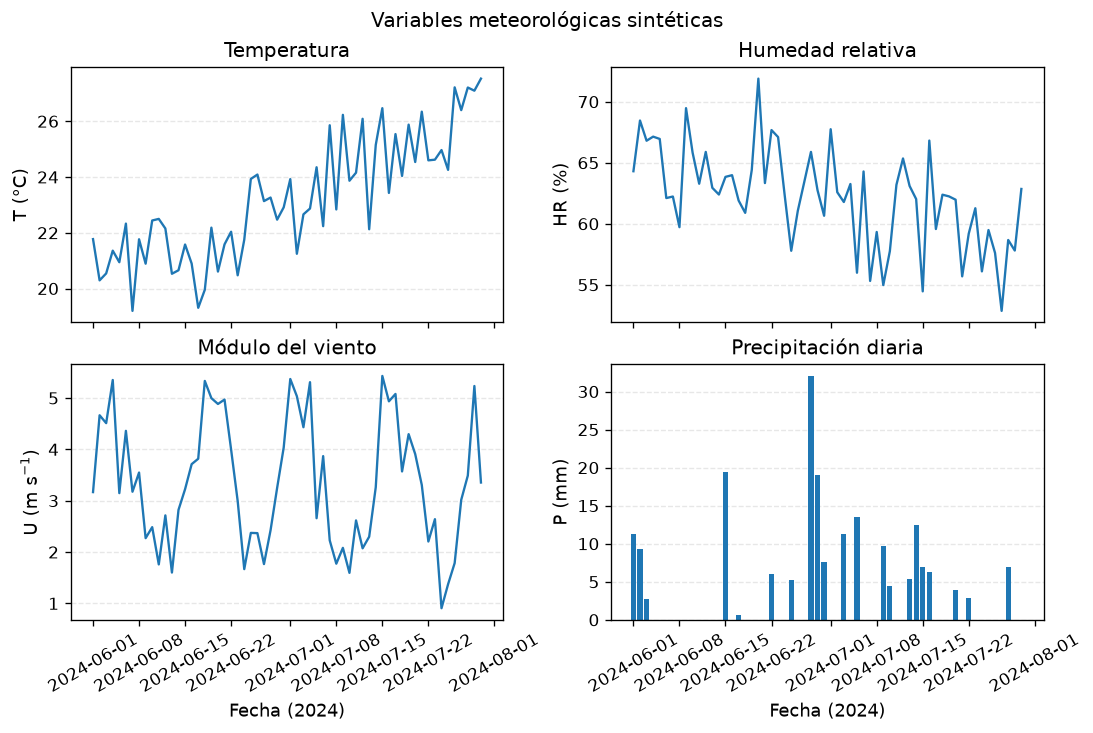

In [12]:
# 3.2 Rejilla de cuatro variables. Solo compartimos el tiempo, no sus unidades.
fig, axes = plt.subplots(
    2, 2, figsize=(9, 6), sharex=True, sharey=False, layout="constrained"
)
ax11, ax12 = axes[0, 0], axes[0, 1]
ax21, ax22 = axes[1, 0], axes[1, 1]

ax11.plot(fechas, T, linewidth=1.4)
ax11.set_title("Temperatura")
ax11.set_ylabel("T (°C)")

ax12.plot(fechas, HR, linewidth=1.4)
ax12.set_title("Humedad relativa")
ax12.set_ylabel("HR (%)")

ax21.plot(fechas, U, linewidth=1.4)
ax21.set_title("Módulo del viento")
ax21.set_ylabel(r"U (m s$^{-1}$)")

ax22.bar(fechas, P, width=0.8)
ax22.set_title("Precipitación diaria")
ax22.set_ylabel("P (mm)")

# .flat permite recorrer un array de paneles sin escribir un bucle por fila.
for ax in axes.flat:
    ax.grid(True, axis="y", linestyle="--", alpha=0.3)
for ax in axes[1, :]:
    ax.set_xlabel("Fecha (2024)")
    ax.tick_params(axis="x", labelrotation=30)

fig.suptitle("Variables meteorológicas sintéticas")
plt.show()

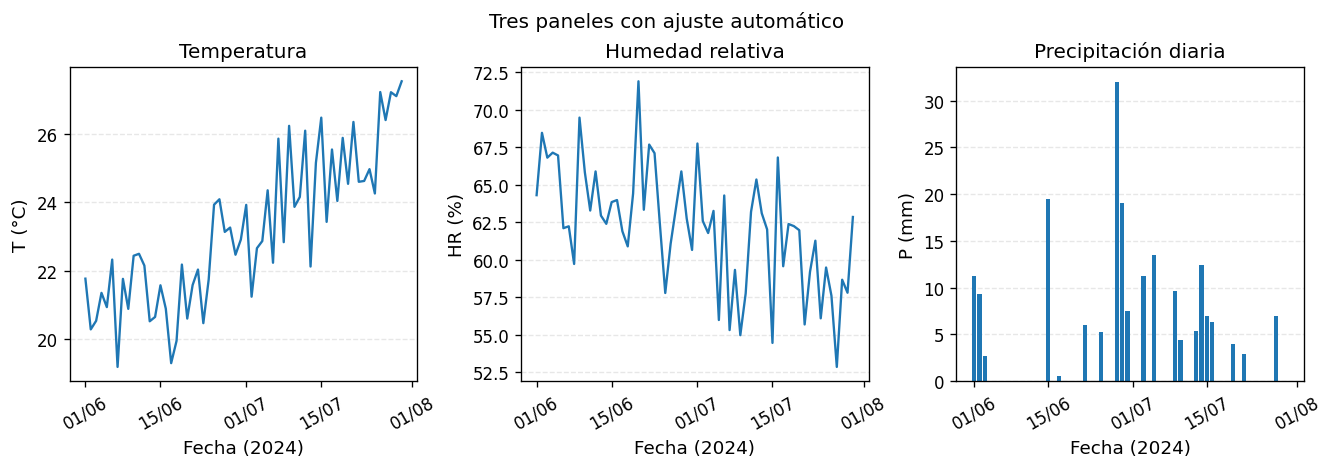

In [8]:
# 3.3 El gestor constrained distribuye automáticamente el espacio.
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), layout="constrained")
ax1, ax2, ax3 = axes

ax1.plot(fechas, T, linewidth=1.4)
ax1.set_title("Temperatura")
ax1.set_ylabel("T (°C)")

ax2.plot(fechas, HR, linewidth=1.4)
ax2.set_title("Humedad relativa")
ax2.set_ylabel("HR (%)")

ax3.bar(fechas, P, width=0.8)
ax3.set_title("Precipitación diaria")
ax3.set_ylabel("P (mm)")

for ax in axes:
    # Cada panel es estrecho. Reducimos las marcas y usamos fechas compactas.
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3, maxticks=4))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax.set_xlabel("Fecha (2024)")
    ax.tick_params(axis="x", labelrotation=30)
    ax.grid(True, axis="y", linestyle="--", alpha=0.3)

fig.suptitle("Tres paneles con ajuste automático")
plt.show()

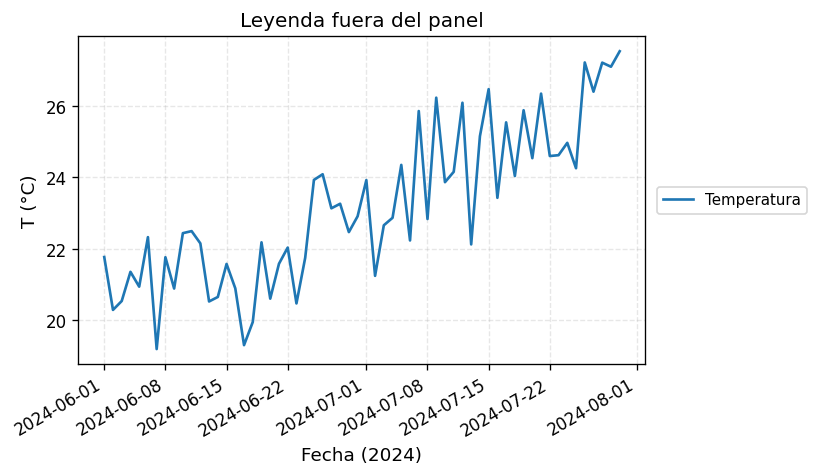

In [9]:
# 3.4 Ajuste manual para reservar espacio a una leyenda exterior.
fig, ax = plt.subplots(figsize=(7.5, 4.2), layout=None)
ax.plot(fechas, T, linewidth=1.6, label="Temperatura")
ax.set_title("Leyenda fuera del panel")
ax.set_xlabel("Fecha (2024)")
ax.set_ylabel("T (°C)")
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),  # Posición relativa al panel; x > 1 queda fuera.
    borderaxespad=0,
)

# No hay un gestor automático activo que compita con estos márgenes.
fig.subplots_adjust(left=0.10, right=0.73, top=0.88, bottom=0.23)
fig.autofmt_xdate(rotation=30, bottom=0.23)
plt.show()

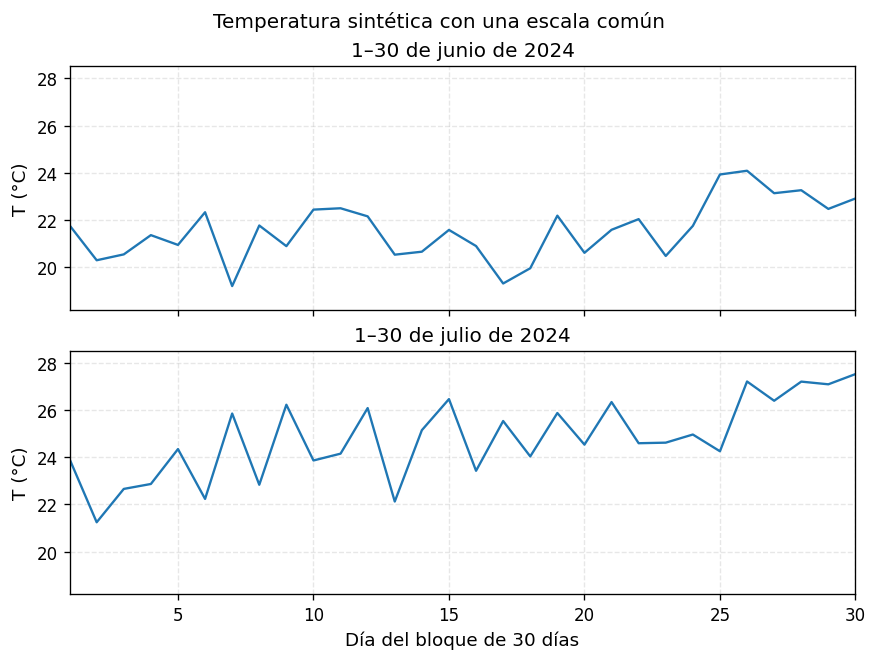

In [10]:
# 3.5 Compartir también el eje vertical al comparar la misma magnitud.
# Comparamos dos bloques de 30 días, no dos meses completos.
dias_bloque = np.arange(1, 31)
fig, (ax_a, ax_b) = plt.subplots(
    2, 1, figsize=(7.2, 5.4), sharex=True, sharey=True, layout="constrained"
)
ax_a.plot(dias_bloque, T[:30], linewidth=1.4)
ax_a.set_title("1–30 de junio de 2024")
ax_b.plot(dias_bloque, T[30:60], linewidth=1.4)
ax_b.set_title("1–30 de julio de 2024")
ax_b.set_xlabel("Día del bloque de 30 días")

for ax in (ax_a, ax_b):
    ax.set_ylabel("T (°C)")
    ax.grid(True, linestyle="--", alpha=0.3)

# El cambio se propaga al otro panel porque comparten el eje Y.
ax_a.set_ylim(T.min() - 1, T.max() + 1)
ax_a.set_xlim(1, 30)
fig.suptitle("Temperatura sintética con una escala común")
plt.show()

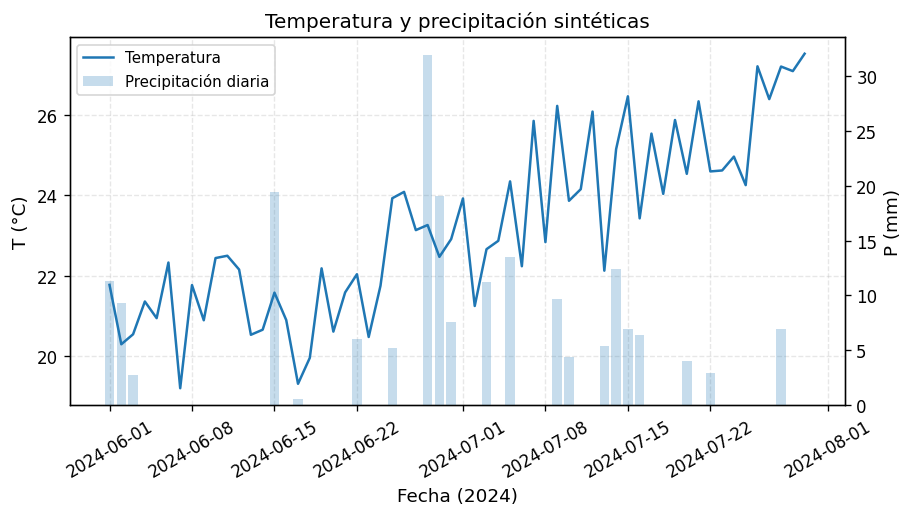

In [11]:
# 3.6 Un segundo eje vertical permite mostrar magnitudes con unidades distintas.
fig, ax_left = plt.subplots(figsize=(7.5, 4.2), layout="constrained")
ax_right = ax_left.twinx()  # Comparte X, pero conserva una escala Y independiente.

ax_left.plot(fechas, T, linewidth=1.5, label="Temperatura")
ax_right.bar(fechas, P, width=0.8, alpha=0.25, label="Precipitación diaria")
ax_left.set_title("Temperatura y precipitación sintéticas")
ax_left.set_xlabel("Fecha (2024)")
ax_left.set_ylabel("T (°C)")
ax_right.set_ylabel("P (mm)")
ax_left.tick_params(axis="x", labelrotation=30)
ax_left.grid(True, linestyle="--", alpha=0.3)

# Una leyenda conjunta necesita recoger los elementos de ambos paneles superpuestos.
handles_left, labels_left = ax_left.get_legend_handles_labels()
handles_right, labels_right = ax_right.get_legend_handles_labels()
ax_left.legend(handles_left + handles_right, labels_left + labels_right, loc="upper left")

# Las alturas de ambas variables no son comparables entre sí; dependen de escalas distintas.
plt.show()

Figura guardada en figuras_matplotlib/fig_multipanel_T_HR.png


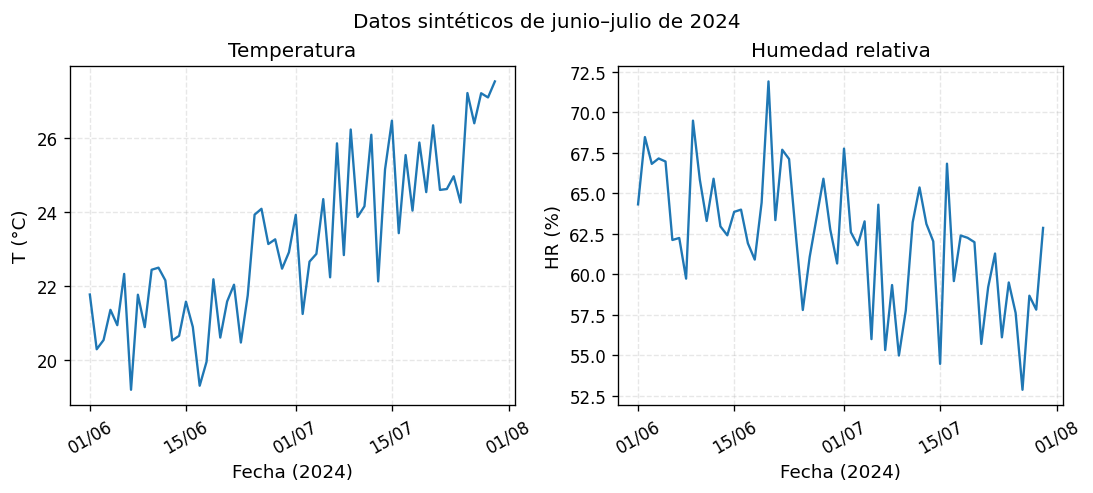

In [12]:
# 3.7 Exportar una figura compuesta con el espacio ya organizado.
fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
ax_l.plot(fechas, T, linewidth=1.4)
ax_l.set_title("Temperatura")
ax_l.set_ylabel("T (°C)")
ax_r.plot(fechas, HR, linewidth=1.4)
ax_r.set_title("Humedad relativa")
ax_r.set_ylabel("HR (%)")

for ax in (ax_l, ax_r):
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3, maxticks=5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax.set_xlabel("Fecha (2024)")
    ax.tick_params(axis="x", labelrotation=30)
    ax.grid(True, linestyle="--", alpha=0.3)
fig.suptitle("Datos sintéticos de junio–julio de 2024")

carpeta_figuras.mkdir(exist_ok=True)
ruta_multipanel = carpeta_figuras / "fig_multipanel_T_HR.png"
fig.savefig(ruta_multipanel, dpi=300, bbox_inches="tight")
print(f"Figura guardada en {ruta_multipanel}")
plt.show()

## 4. Etiquetado científico

Una figura debe permitir reconocer **qué se representa, en qué unidades y durante qué periodo**, sin depender de explicaciones que solo conozca quien la ha preparado. El título, las etiquetas y las anotaciones cumplen funciones distintas y conviene que se complementen.

<div style="padding: 0.8em 1em; margin: 0.8em 0 1.2em; border-left: 4px solid #4C78A8; background-color: rgba(76,120,168,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.45em 0;">El <strong>título</strong> sitúa el contenido de la figura. Las <strong>etiquetas de los ejes</strong> identifican las magnitudes y sus unidades. La <strong>leyenda</strong> distingue las series, y las <strong>anotaciones</strong> señalan valores o intervalos concretos.</p>
</div>

Un título como «Temperatura diaria — Datos sintéticos, junio–julio de 2024» identifica la variable, el periodo y la naturaleza de los datos. En figuras multipanel, `fig.suptitle()` puede recoger el contexto común y `ax.set_title()` describir cada panel.

**Magnitudes y unidades**

| Etiqueta | Interpretación |
| --- | --- |
| `Temperatura (°C)` | Temperatura expresada en grados Celsius. |
| `Humedad relativa (%)` | Humedad relativa expresada en porcentaje. |
| `U (m·s⁻¹)` | Módulo del viento en metros por segundo. |
| `Precipitación diaria (mm)` | Cantidad acumulada durante cada día, no una intensidad instantánea. |

Podemos escribir expresiones matemáticas entre signos `$` mediante **Mathtext**, sin instalar LaTeX. Por ejemplo, `ax.set_ylabel(r"U (m s$^{-1}$)")` muestra el exponente −1. La `r` indica una cadena de texto literal, útil cuando contiene barras invertidas.

**Leyendas que faciliten la comparación**

Una sola serie bien identificada por el título y el eje puede no necesitar leyenda. Si hay varias, usamos nombres breves y estilos distinguibles. Para practicar compararemos versiones suavizadas de la misma temperatura, en lugar de superponer temperatura y humedad sobre una escala sin unidades comunes.

`ax.plot()` devuelve una lista de objetos de línea. En `linea, = ax.plot(...)`, la coma extrae el único elemento de esa lista. Guardar estos objetos permite cambiar el orden de la leyenda mediante `ax.legend(handles, labels)`. `ax.bar()` devuelve un contenedor de barras que también puede incorporarse a una leyenda.

**Anotaciones y referencias**

`ax.annotate()` relaciona un texto con un punto. `xy` identifica el dato y `xytext` indica dónde colocar el texto. Con `textcoords="offset points"`, el desplazamiento se expresa en **puntos tipográficos**, no en píxeles; un punto equivale a 1/72 de pulgada. También podemos situar el texto en coordenadas relativas al panel mediante `textcoords="axes fraction"`.

Las funciones `ax.axhline()`, `ax.axvline()` y `ax.axvspan()` dibujan una línea horizontal, una vertical y una franja temporal, respectivamente. En los ejemplos fijamos un umbral térmico ilustrativo y destacamos un intervalo de tres días elegido para mostrar estas herramientas.

<div style="padding: 0.8em 1em; margin: 0.8em 0 1.2em; border-left: 4px solid #B88632; background-color: rgba(184,134,50,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.45em 0;"><strong>Interpretación.</strong> Un máximo de la serie es el mayor valor de esa muestra, no un récord climático. Del mismo modo, sombrear unas fechas no demuestra que haya una borrasca o una ola de calor. El texto de la anotación debe ajustarse a lo que realmente sabemos de los datos.</p>
</div>

<p style="font-size: 0.9em; margin: 1em 0 0.3em;"><a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.annotate.html">Anotaciones y coordenadas</a></p>

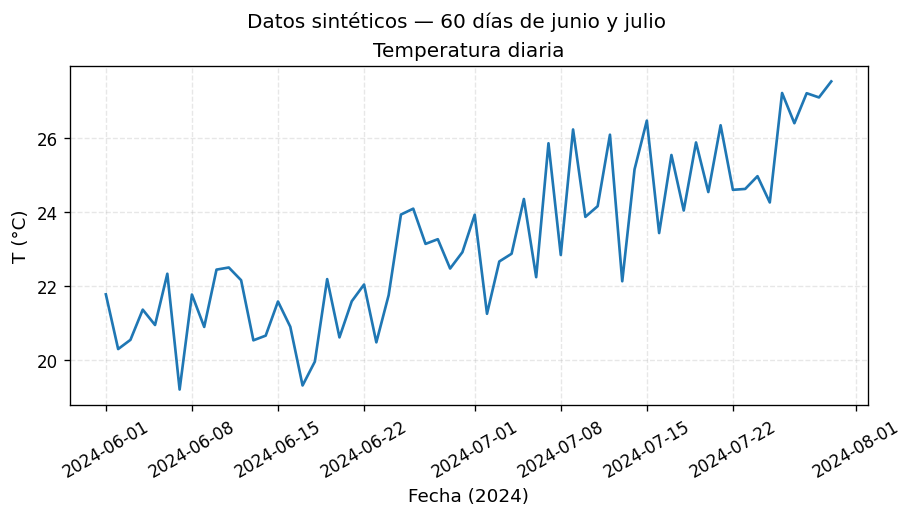

In [13]:
# 4.1 El título global aporta el contexto y el título del panel identifica la variable.
fig, ax = plt.subplots(figsize=(7.5, 4.2), layout="constrained")
ax.plot(fechas, T, linewidth=1.6)
ax.set_title("Temperatura diaria")
ax.set_xlabel("Fecha (2024)")
ax.set_ylabel("T (°C)")
ax.tick_params(axis="x", labelrotation=30)
ax.grid(True, linestyle="--", alpha=0.3)
fig.suptitle("Datos sintéticos — 60 días de junio y julio")
plt.show()

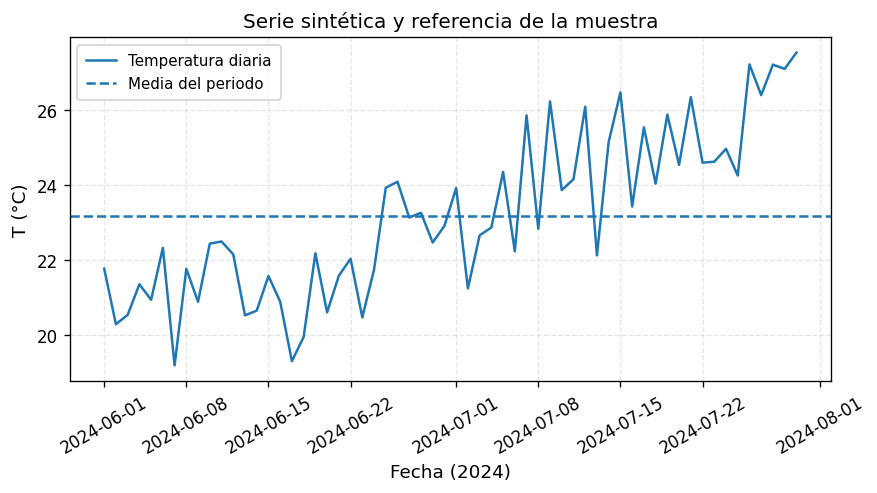

In [14]:
# 4.2 La leyenda distingue dos referencias expresadas en la misma unidad.
fig, ax = plt.subplots(figsize=(7.2, 4), layout="constrained")
ax.plot(fechas, T, linewidth=1.5, label="Temperatura diaria")
ax.axhline(T.mean(), linestyle="--", linewidth=1.5, label="Media del periodo")
ax.set_title("Serie sintética y referencia de la muestra")
ax.set_xlabel("Fecha (2024)")
ax.set_ylabel("T (°C)")
ax.tick_params(axis="x", labelrotation=30)
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(
    loc="best",  # Busca una ubicación con poca superposición, sin garantizarla.
    frameon=True,
    fancybox=True,
    framealpha=0.85,
    borderpad=0.6,
)
plt.show()

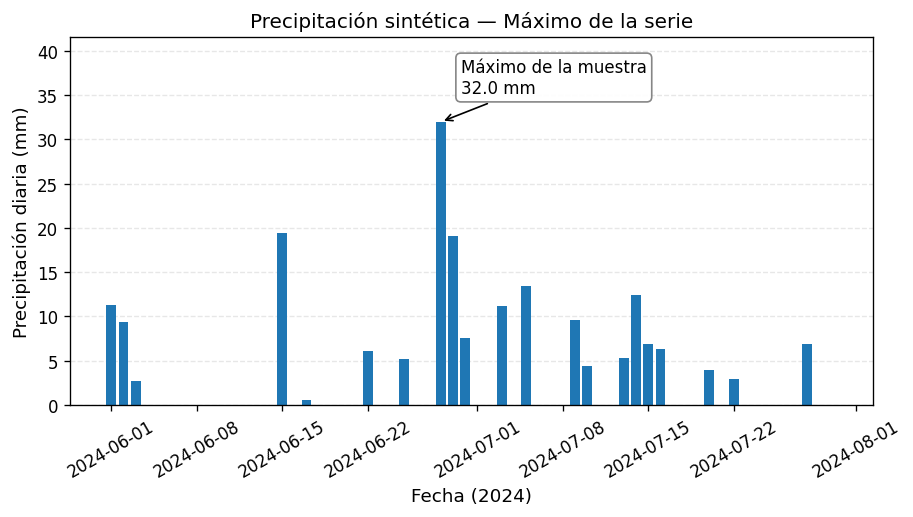

In [15]:
# 4.3 Una anotación vinculada al mayor acumulado diario de la muestra.
i_maxP = int(np.argmax(P))  # En caso de empate, devuelve la primera posición.
fecha_maxP, valor_maxP = fechas[i_maxP], P[i_maxP]

fig, ax = plt.subplots(figsize=(7.5, 4.2), layout="constrained")
ax.bar(fechas, P, width=0.8)
ax.set_title("Precipitación sintética — Máximo de la serie")
ax.set_xlabel("Fecha (2024)")
ax.set_ylabel("Precipitación diaria (mm)")
ax.tick_params(axis="x", labelrotation=30)
ax.grid(True, axis="y", linestyle="--", alpha=0.3)
ax.set_ylim(0, P.max() * 1.30)  # Reserva espacio para el texto sin tapar las barras.

# Colocamos el texto hacia el interior si el máximo está en la mitad derecha.
hacia_derecha = i_maxP < len(P) / 2
desplazamiento_x = 12 if hacia_derecha else -12
ax.annotate(
    f"Máximo de la muestra\n{valor_maxP:.1f} mm",
    xy=(fecha_maxP, valor_maxP),
    xytext=(desplazamiento_x, 15),
    textcoords="offset points",  # Desplazamiento en puntos tipográficos, no píxeles.
    arrowprops={"arrowstyle": "->", "lw": 1},
    bbox={"boxstyle": "round,pad=0.3", "fc": "white", "ec": "0.5", "alpha": 0.95},
    ha="left" if hacia_derecha else "right",
    va="bottom",
)
plt.show()

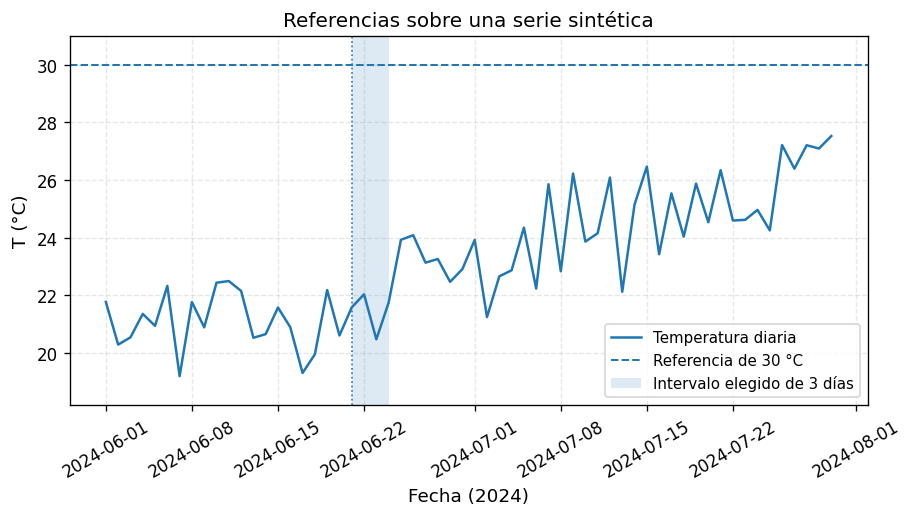

In [16]:
# 4.4 Línea horizontal, línea vertical y franja de tres días.
umbral_T = 30.0  # Referencia ilustrativa, no criterio de ola de calor.
inicio_ep = 20
duracion_ep = 3
fecha_ini_ep = fechas[inicio_ep]
fecha_fin_ep = fecha_ini_ep + np.timedelta64(duracion_ep, "D")

fig, ax = plt.subplots(figsize=(7.5, 4.2), layout="constrained")
ax.plot(fechas, T, linewidth=1.5, label="Temperatura diaria")
ax.axhline(umbral_T, linestyle="--", linewidth=1.2, label="Referencia de 30 °C")
ax.axvline(fecha_ini_ep, linestyle=":", linewidth=1)
# La franja va desde el inicio del primer día hasta el inicio del cuarto.
ax.axvspan(fecha_ini_ep, fecha_fin_ep, alpha=0.15, label="Intervalo elegido de 3 días")
ax.set_title("Referencias sobre una serie sintética")
ax.set_xlabel("Fecha (2024)")
ax.set_ylabel("T (°C)")
ax.set_ylim(T.min() - 1, umbral_T + 1)
ax.tick_params(axis="x", labelrotation=30)
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(loc="lower right")
plt.show()

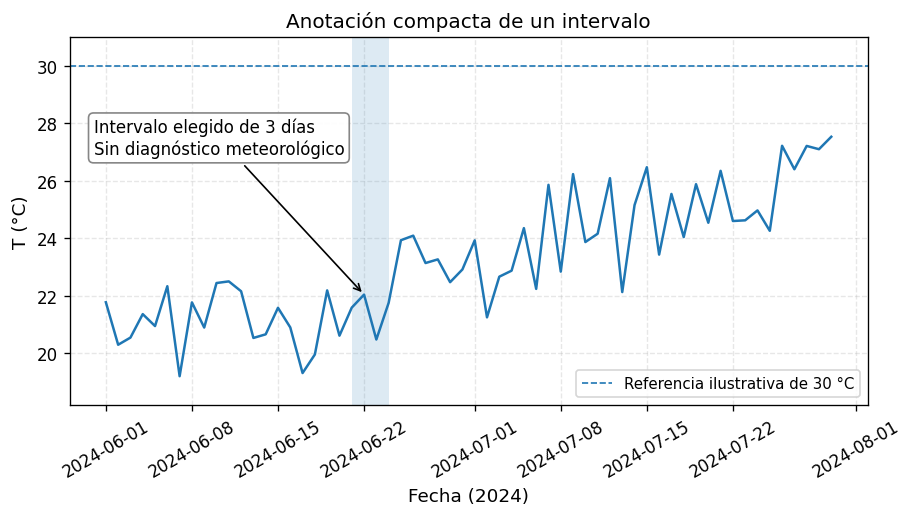

In [17]:
# 4.5 Situar el texto en una región del panel, sin asignar un fenómeno real a los datos.
inicio_ep = 20
duracion_ep = 3
fecha_ini_ep = fechas[inicio_ep]
fecha_fin_ep = fecha_ini_ep + np.timedelta64(duracion_ep, "D")

fig, ax = plt.subplots(figsize=(7.5, 4.2), layout="constrained")
ax.plot(fechas, T, linewidth=1.5)
ax.axhline(30, linestyle="--", linewidth=1, label="Referencia ilustrativa de 30 °C")
ax.axvspan(fecha_ini_ep, fecha_fin_ep, alpha=0.15)
ax.annotate(
    "Intervalo elegido de 3 días\nSin diagnóstico meteorológico",
    xy=(fechas[inicio_ep + 1], T[inicio_ep + 1]),
    xytext=(0.03, 0.78),
    textcoords="axes fraction",  # Posición relativa al panel, entre 0 y 1.
    arrowprops={"arrowstyle": "->", "lw": 1},
    bbox={"boxstyle": "round,pad=0.3", "fc": "white", "ec": "0.5", "alpha": 0.95},
    ha="left", va="top",
)
ax.set_title("Anotación compacta de un intervalo")
ax.set_xlabel("Fecha (2024)")
ax.set_ylabel("T (°C)")
ax.set_ylim(T.min() - 1, 31)
ax.tick_params(axis="x", labelrotation=30)
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(loc="lower right")
plt.show()

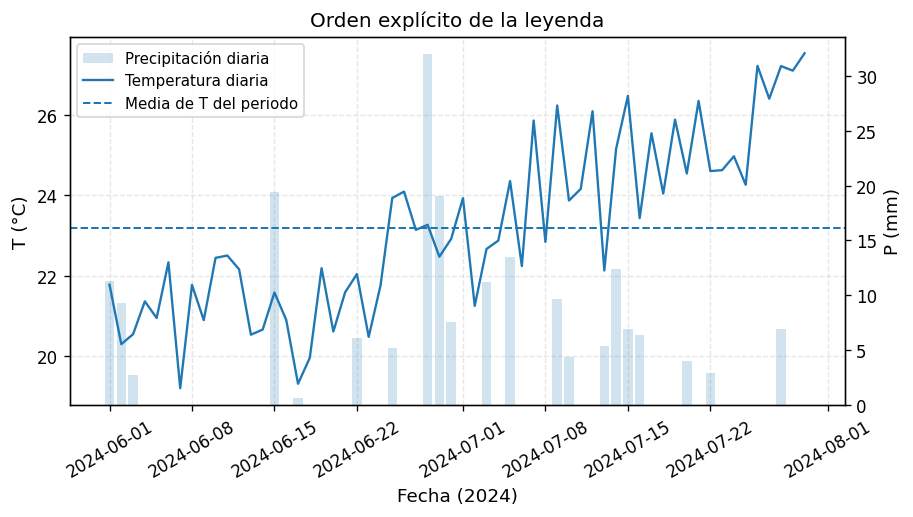

In [18]:
# 4.6 Seleccionar y ordenar los objetos de una leyenda conjunta.
fig, ax = plt.subplots(figsize=(7.5, 4.2), layout="constrained")
ax_p = ax.twinx()
linea_T, = ax.plot(fechas, T, linewidth=1.4)
linea_media = ax.axhline(T.mean(), linestyle="--", linewidth=1.2)
barras_P = ax_p.bar(fechas, P, width=0.8, alpha=0.2)

ax.set_title("Orden explícito de la leyenda")
ax.set_xlabel("Fecha (2024)")
ax.set_ylabel("T (°C)")
ax_p.set_ylabel("P (mm)")
ax.tick_params(axis="x", labelrotation=30)
ax.grid(True, linestyle="--", alpha=0.3)

# La lista combina un contenedor de barras y dos objetos de línea.
handles = [barras_P, linea_T, linea_media]
labels = ["Precipitación diaria", "Temperatura diaria", "Media de T del periodo"]
ax.legend(handles, labels, loc="upper left")
plt.show()

## 5. Gestión del tiempo y de las fechas con `mdates`

Las fechas contienen información a distintas escalas, como años, meses, días u horas. Mostrar todos esos detalles en cada marca puede producir etiquetas largas y superpuestas. El módulo `matplotlib.dates`, que importamos como `mdates`, permite elegir qué mostrar y dónde hacerlo.

<div style="padding: 0.8em 1em; margin: 0.8em 0 1.2em; border-left: 4px solid #4C78A8; background-color: rgba(76,120,168,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.45em 0;">Un <strong>localizador</strong> determina dónde aparecen las marcas del eje, también llamadas <em>ticks</em>. Un <strong>formateador</strong> convierte la fecha de cada marca en una etiqueta legible. Cambiar la posición de las marcas y cambiar el texto que muestran son operaciones diferentes.</p>
</div>

| Herramienta | Función |
| --- | --- |
| `AutoDateLocator` | Elige intervalos de marcas según el rango temporal. |
| `MonthLocator` | Coloca marcas en determinados días del mes; por defecto, el día 1. |
| `DayLocator` | Sitúa marcas con una separación de días configurable. |
| `WeekdayLocator` | Selecciona días de la semana, como los lunes con `mdates.MO`. |
| `ConciseDateFormatter` | Reduce la información repetida y conserva el contexto temporal. |
| `DateFormatter` | Aplica un patrón de texto definido por nosotros. |

Una combinación habitual es `AutoDateLocator` con `ConciseDateFormatter`. El formateador recibe el mismo localizador que asignamos al eje, de modo que puede adaptar las etiquetas a sus marcas.

```python
locator = mdates.AutoDateLocator(minticks=4, maxticks=7)
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)
```

Los valores `minticks` y `maxticks` orientan la selección automática. La legibilidad también depende del tamaño de la figura, por lo que conviene comprobar el resultado. En paneles independientes creamos localizadores distintos, ya que cada objeto queda asociado a un eje.

**Marcas principales y secundarias**

Las marcas principales suelen llevar etiquetas. Las secundarias añaden referencias más discretas, por ejemplo días entre los inicios de mes. `which="major"` y `which="minor"` permiten ajustar su aspecto y el de las cuadrículas por separado.

**Formatos personalizados e idioma**

En `DateFormatter`, `%d` representa el día, `%m` el mes numérico, `%b` el mes abreviado y `%Y` el año con cuatro cifras. El patrón `%d/%m` muestra fechas como `15/06` sin depender del idioma del sistema. `%b` sí depende de la configuración regional.

Podemos solicitar nombres de meses en castellano mediante `locale.setlocale(locale.LC_TIME, "es_ES.UTF-8")`, pero esa configuración debe estar instalada y su identificador puede variar entre sistemas. Si no existe, Python lanza `locale.Error`; no cambia de idioma automáticamente. Los ejemplos usan formatos numéricos cuando interesa evitar esa dependencia.

**Ventanas temporales y rotación**

`ax.set_xlim(inicio, fin)` cambia la parte de la serie que vemos, pero no recorta ni modifica los arrays originales. Para aliviar el solapamiento podemos reducir el número de marcas o rotar sus etiquetas con `ax.tick_params(axis="x", labelrotation=30)`.

<div style="padding: 0.8em 1em; margin: 0.8em 0 1.2em; border-left: 4px solid #59A14F; background-color: rgba(89,161,79,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.45em 0;"><strong>Conservar el contexto.</strong> <code>ConciseDateFormatter</code> puede mostrar el año o el mes en un texto adicional junto al eje. No conviene ocultarlo sin aportar esa información en otro lugar, porque unas etiquetas compactas podrían quedar ambiguas.</p>
</div>

<p style="font-size: 0.9em; margin: 1em 0 0.3em;"><a href="https://matplotlib.org/stable/api/dates_api.html">Fechas en Matplotlib</a></p>

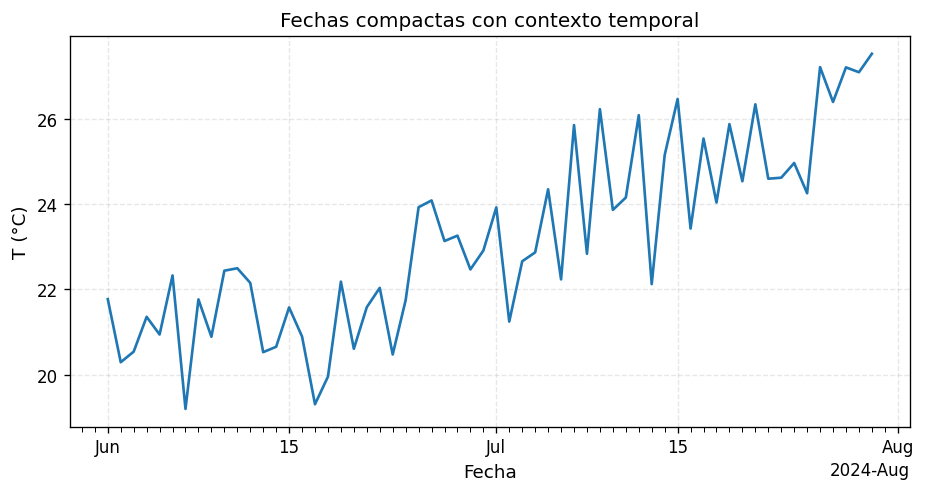

In [19]:
# 5.1 El localizador y el formateador trabajan juntos.
fig, ax = plt.subplots(figsize=(7.6, 4), layout="constrained")
ax.plot(fechas, T, linewidth=1.6)
ax.set_title("Fechas compactas con contexto temporal")
ax.set_xlabel("Fecha")
ax.set_ylabel("T (°C)")

locator = mdates.AutoDateLocator(minticks=4, maxticks=7)
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)
# Conservamos el texto adicional que aporta el año o el mes.
ax.xaxis.set_minor_locator(mdates.DayLocator(interval=1))
ax.tick_params(axis="x", which="minor", length=3)
ax.grid(True, which="major", linestyle="--", alpha=0.3)
plt.show()

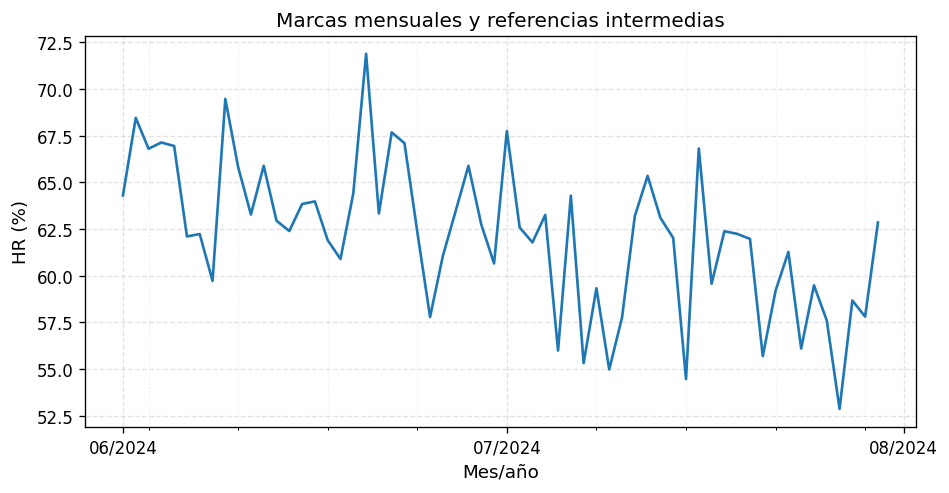

In [20]:
# 5.2 Marcas principales al inicio de mes y secundarias cada siete días.
fig, ax = plt.subplots(figsize=(7.8, 4), layout="constrained")
ax.plot(fechas, HR, linewidth=1.6)
ax.set_title("Marcas mensuales y referencias intermedias")
ax.set_xlabel("Mes/año")
ax.set_ylabel("HR (%)")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonthday=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.xaxis.set_minor_locator(mdates.DayLocator(interval=7))
ax.grid(True, which="major", linestyle="--", alpha=0.35)
ax.grid(True, which="minor", axis="x", linestyle=":", alpha=0.20)
plt.show()

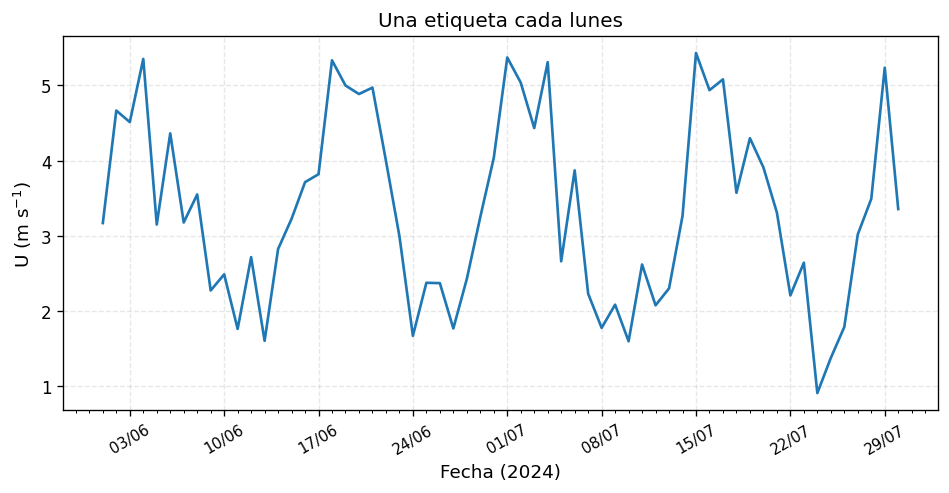

In [21]:
# 5.3 El día de la semana se selecciona con WeekdayLocator.
fig, ax = plt.subplots(figsize=(7.8, 4), layout="constrained")
ax.plot(fechas, U, linewidth=1.6)
ax.set_title("Una etiqueta cada lunes")
ax.set_xlabel("Fecha (2024)")
ax.set_ylabel(r"U (m s$^{-1}$)")
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.xaxis.set_minor_locator(mdates.DayLocator())
ax.tick_params(axis="x", labelrotation=30, labelsize=9)
ax.grid(True, which="major", linestyle="--", alpha=0.3)
plt.show()

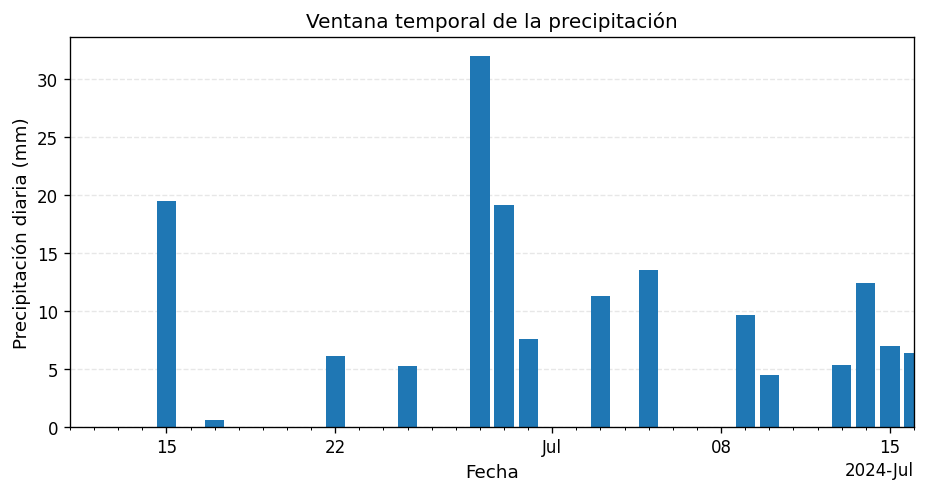

In [22]:
# 5.4 Cambiar el intervalo visible no modifica las series.
fig, ax = plt.subplots(figsize=(7.6, 4), layout="constrained")
ax.bar(fechas, P, width=0.8)
ax.set_title("Ventana temporal de la precipitación")
ax.set_xlabel("Fecha")
ax.set_ylabel("Precipitación diaria (mm)")
ax.set_xlim(fechas[10], fechas[45])

locator = mdates.AutoDateLocator(minticks=4, maxticks=7)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.xaxis.set_minor_locator(mdates.DayLocator())
ax.grid(True, axis="y", linestyle="--", alpha=0.3)
plt.show()

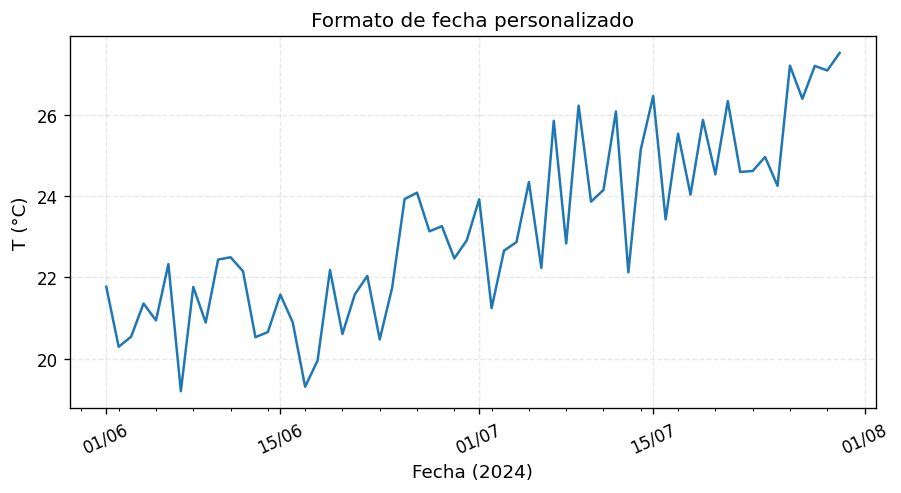

In [23]:
# 5.5 Un patrón numérico evita depender del idioma del sistema.
fig, ax = plt.subplots(figsize=(7.4, 4), layout="constrained")
ax.plot(fechas, T, linewidth=1.5)
ax.set_title("Formato de fecha personalizado")
ax.set_xlabel("Fecha (2024)")
ax.set_ylabel("T (°C)")
ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=7))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.xaxis.set_minor_locator(mdates.DayLocator(interval=3))
# Sustituir %m por %b mostraría el mes abreviado según la configuración regional.
ax.tick_params(axis="x", labelrotation=25)
ax.grid(True, linestyle="--", alpha=0.3)
plt.show()

## 6. Estilos, grosores y marcadores

El estilo debe ayudar a distinguir los datos, no competir con ellos. El grosor, el patrón de línea y los marcadores permiten reconocer una serie incluso cuando los colores resultan difíciles de diferenciar o la figura se imprime en escala de grises.

| Parámetro | Qué controla | Ejemplo |
| --- | --- | --- |
| `color` | Color de una línea o unos marcadores. | `"C0"` toma el primer color del ciclo. |
| `linewidth` o `lw` | Grosor de línea, en puntos tipográficos. | `linewidth=1.5` |
| `linestyle` o `ls` | Patrón de línea. | `"-"`, `"--"`, `":"`, `"-."` |
| `marker` | Símbolo situado sobre cada dato. | `"o"`, `"s"`, `"^"` |
| `markersize` o `ms` | Tamaño del marcador en `plot`, en puntos. | `markersize=4` |
| `s` | Área del marcador en `scatter`, en puntos cuadrados. | `s=25` |
| `markerfacecolor`, `markeredgecolor` | Relleno y borde del marcador en `plot`. | `markerfacecolor="none"` lo deja hueco. |
| `markeredgewidth` | Grosor del borde del marcador en `plot`. | `markeredgewidth=1` |
| `alpha` | Opacidad entre 0 y 1. | `alpha=0.4` deja ver mejor los solapamientos. |
| `zorder` | Orden de dibujo dentro de un mismo panel. | Un valor mayor sitúa el elemento por encima. |

<div style="padding: 0.8em 1em; margin: 0.8em 0 1.2em; border-left: 4px solid #59A14F; background-color: rgba(89,161,79,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.45em 0;"><strong>Tamaño y transparencia.</strong> <code>markersize=5</code> y <code>s=5</code> no expresan lo mismo. El primero especifica un tamaño lineal y el segundo un área. Además, reducir <code>alpha</code> aumenta la transparencia; subirlo acerca el elemento a la opacidad completa.</p>
</div>

**Estilos locales y ciclos de propiedades**

Si no indicamos un color, Matplotlib usa su ciclo de propiedades. Podemos construir otro con `cycler` y asignarlo a un panel mediante `ax.set_prop_cycle()`. Así el cambio queda limitado a ese gráfico. Modificar `plt.rcParams` afectaría a los paneles creados posteriormente.

En el ejemplo combinaremos tres colores del ciclo disponible con tres patrones de línea. La suma de ciclos con `+` empareja sus elementos y requiere que tengan la misma longitud. No genera todas las combinaciones posibles.

**Colores para campos bidimensionales**

Un **mapa de color** asocia valores numéricos con colores. Las paletas secuenciales, como `viridis` y `cividis`, son útiles para magnitudes ordenadas de menor a mayor. Cuando importa distinguir valores a ambos lados de una referencia, puede ser apropiada una paleta divergente centrada en esa referencia. La elección debe responder a la variable y a la comparación que queremos realizar.

`vmin` y `vmax` fijan el rango numérico de la escala. Usaremos el mismo rango al comparar dos paletas. Limitarlo a los percentiles 5 y 95 aumenta el contraste en la parte central de la muestra, pero **satura los valores exteriores** y deja de distinguir sus magnitudes. No elimina datos ni demuestra que sean errores. Las extensiones de la barra de color señalarán esa saturación.

**Suavizado y bandas de variabilidad**

Una **media móvil** sustituye cada valor por el promedio de los datos de una ventana cercana. En una serie diaria regular, una ventana centrada de 7 datos comprende el día de referencia, los tres anteriores y los tres posteriores. Elegimos ventanas impares para que el centro coincida con una fecha.

La función `media_movil()` suma los valores válidos y divide por su número. En los extremos utiliza menos datos, en lugar de tratarlos como ceros. También omite valores no finitos y devuelve `NaN` cuando una ventana no contiene ninguno. Esta elección evita diluir artificialmente los extremos, pero allí el suavizado no es idéntico al del interior. En una serie irregular, contar siete datos no equivale necesariamente a abarcar siete días.

La función `desv_movil()` utiliza las mismas ventanas para describir su dispersión. En cada una calcula

$$
\sigma = \sqrt{\frac{1}{n}\sum_{j=1}^{n}(x_j-\overline{x})^2},
$$

donde $n$ es el número de valores válidos. Dividimos por $n$ porque describimos esos datos, sin aplicar la corrección muestral. Tanto la media como la desviación de una temperatura expresada en °C conservan esa unidad.

<div style="padding: 0.8em 1em; margin: 0.8em 0 1.2em; border-left: 4px solid #B88632; background-color: rgba(184,134,50,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.45em 0;"><strong>Variabilidad no es incertidumbre.</strong> La banda de media móvil ± una desviación estándar describe la dispersión local de los datos. No es, por sí sola, un intervalo de confianza de la media ni una estimación del error de medida. <code>fill_between()</code> solo dibuja los límites que le proporcionamos.</p>
</div>

<p style="font-size: 0.9em; margin: 1em 0 0.3em;"><a href="https://matplotlib.org/stable/users/explain/colors/colormaps.html">Elección de mapas de color</a></p>

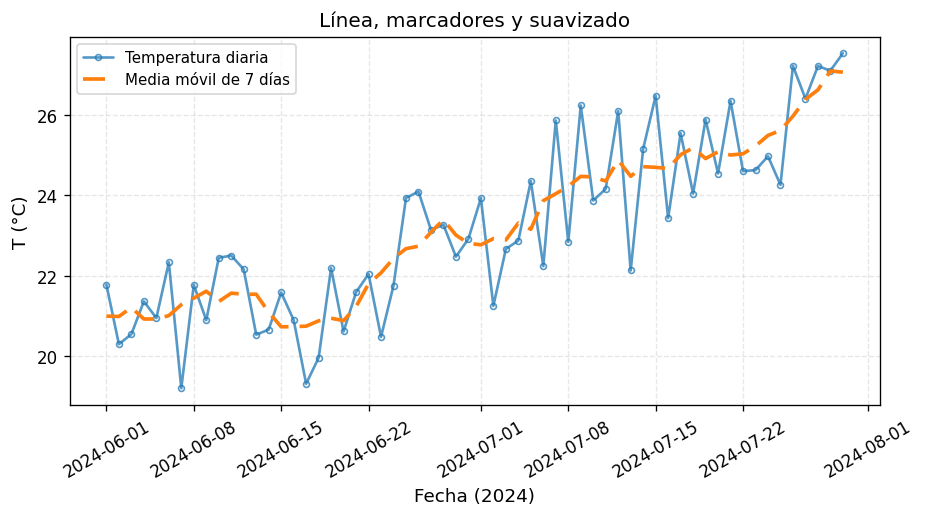

In [24]:
from matplotlib import cycler


def media_movil(x, w: int = 7) -> np.ndarray:
    """Media centrada de una serie 1D con una ventana impar de w datos.

    Omite valores no finitos. En los extremos utiliza los datos disponibles;
    una ventana sin datos válidos devuelve NaN. No modifica la entrada.
    """
    x = np.asarray(x, dtype=float)
    if x.ndim != 1 or x.size == 0:
        raise ValueError("x debe ser una serie unidimensional no vacía.")
    if isinstance(w, (bool, np.bool_)) or not isinstance(w, (int, np.integer)):
        raise TypeError("w debe ser un número entero.")
    if w < 1 or w % 2 == 0 or w > x.size:
        raise ValueError("w debe ser impar, positivo y no superar la longitud de x.")

    validos = np.isfinite(x)
    pesos = np.ones(w)
    # La convolución con unos suma los valores de cada ventana.
    suma = np.convolve(np.where(validos, x, 0.0), pesos, mode="same")
    cuenta = np.convolve(validos.astype(float), pesos, mode="same")
    resultado = np.full(x.shape, np.nan)
    # where evita dividir por cero en las ventanas sin valores válidos.
    np.divide(suma, cuenta, out=resultado, where=cuenta > 0)
    return resultado


# 6.1 Un suavizado facilita comparar el fondo de la serie con las oscilaciones diarias.
T_mm7 = media_movil(T, 7)
fig, ax = plt.subplots(figsize=(7.6, 4.2), layout="constrained")
linea_T, = ax.plot(
    fechas, T,
    color="C0", linewidth=1.6, linestyle="-",
    marker="o", markersize=3.5,
    markerfacecolor="none", markeredgewidth=1,
    alpha=0.75, zorder=2, label="Temperatura diaria",
)
linea_T.set_solid_capstyle("round")
linea_T.set_solid_joinstyle("round")
linea_media, = ax.plot(
    fechas, T_mm7, color="C1", linewidth=2.2,
    zorder=3, label="Media móvil de 7 días",
)
# Seis puntos de trazo y tres de separación, un patrón de guiones personalizado.
linea_media.set_linestyle((0, (6, 3)))
ax.set_title("Línea, marcadores y suavizado")
ax.set_xlabel("Fecha (2024)")
ax.set_ylabel("T (°C)")
ax.tick_params(axis="x", labelrotation=30)
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(loc="best")
plt.show()

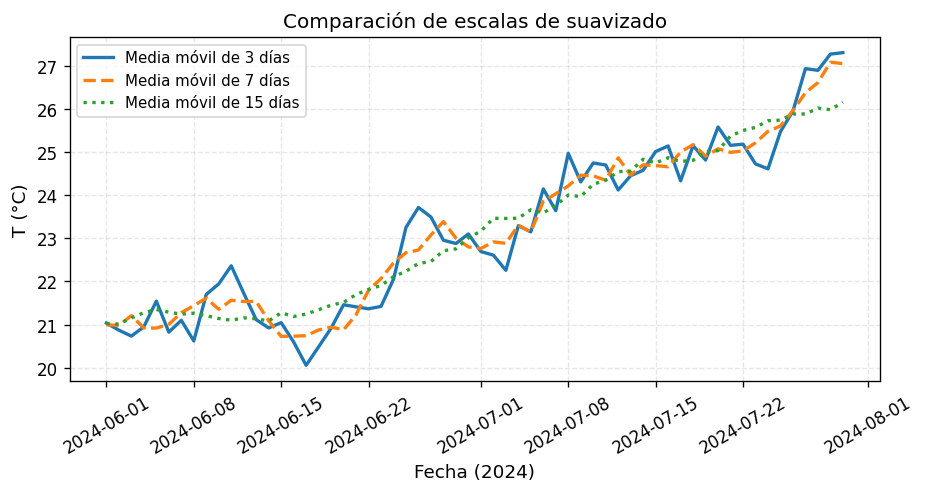

In [25]:
# 6.2 El ciclo de propiedades se limita a este panel.
fig, ax = plt.subplots(figsize=(7.6, 4), layout="constrained")
colores = plt.rcParams["axes.prop_cycle"].by_key()["color"][:3]
ciclo = cycler(color=colores) + cycler(linestyle=["-", "--", ":"])
ax.set_prop_cycle(ciclo)

# Las ventanas impares tienen un centro situado en una fecha de la serie.
for w in (3, 7, 15):
    ax.plot(fechas, media_movil(T, w), linewidth=2, label=f"Media móvil de {w} días")
ax.set_title("Comparación de escalas de suavizado")
ax.set_xlabel("Fecha (2024)")
ax.set_ylabel("T (°C)")
ax.tick_params(axis="x", labelrotation=30)
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(loc="best")
plt.show()

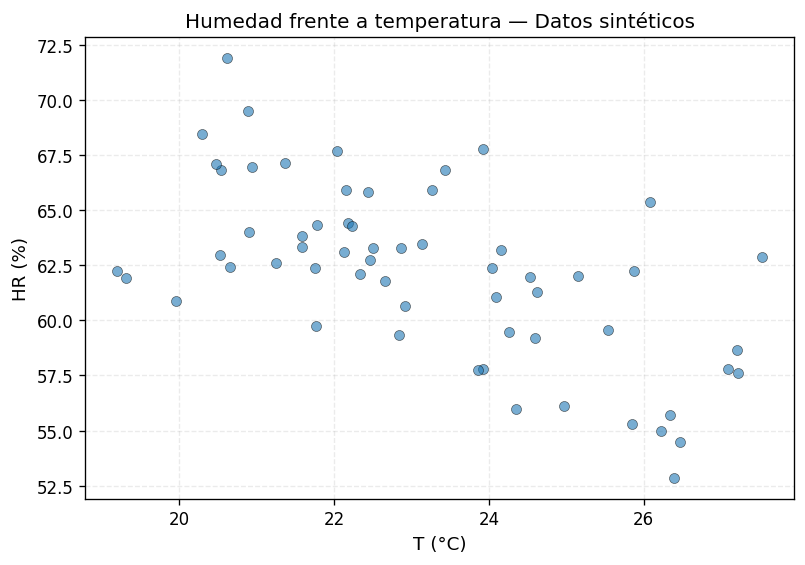

In [26]:
# 6.3 En scatter, s es un área en puntos cuadrados.
fig, ax = plt.subplots(figsize=(6.6, 4.6), layout="constrained")
ax.scatter(T, HR, s=36, marker="o", edgecolors="black", linewidths=0.4, alpha=0.6)
ax.set_title("Humedad frente a temperatura — Datos sintéticos")
ax.set_xlabel("T (°C)")
ax.set_ylabel("HR (%)")
ax.grid(True, linestyle="--", alpha=0.25)
# En una nube más densa, reducir s o alpha ayuda a distinguir los solapamientos.
plt.show()

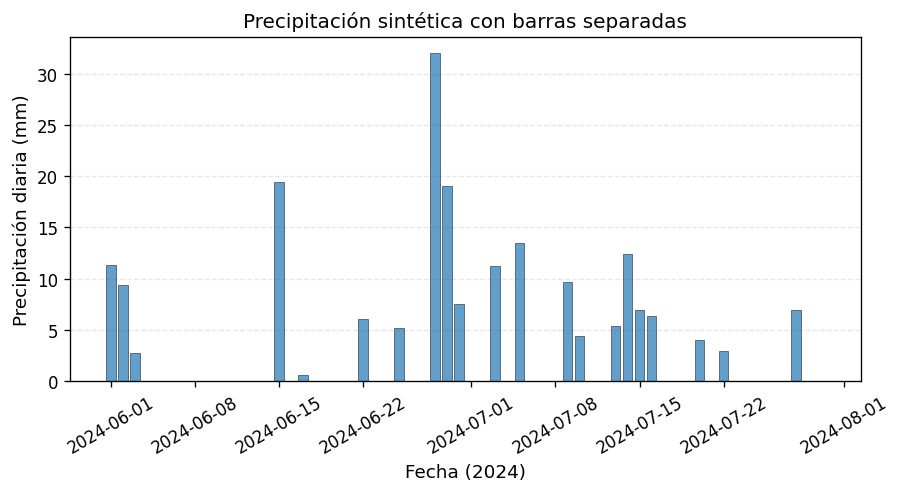

In [27]:
# 6.4 La anchura de las barras temporales se expresa aquí en días.
fig, ax = plt.subplots(figsize=(7.4, 4), layout="constrained")
ax.bar(fechas, P, width=0.8, alpha=0.7, edgecolor="black", linewidth=0.4)
ax.set_title("Precipitación sintética con barras separadas")
ax.set_xlabel("Fecha (2024)")
ax.set_ylabel("Precipitación diaria (mm)")
ax.tick_params(axis="x", labelrotation=30)
ax.grid(True, axis="y", linestyle="--", alpha=0.3)
plt.show()

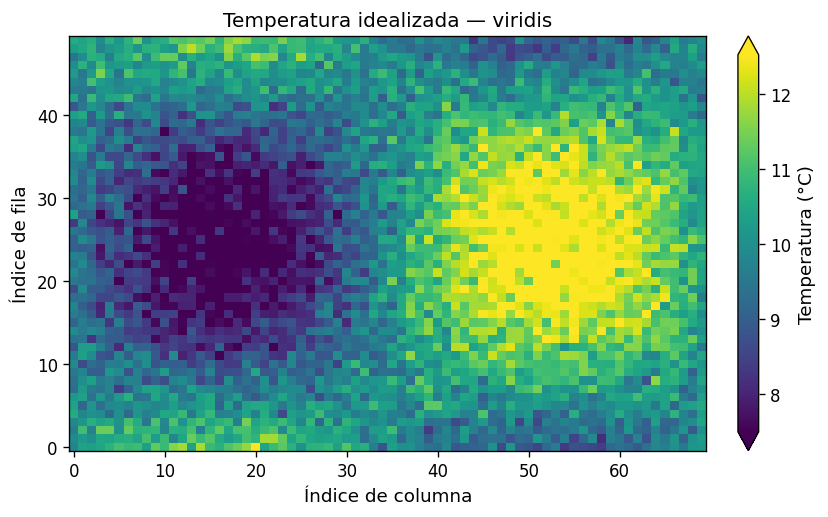

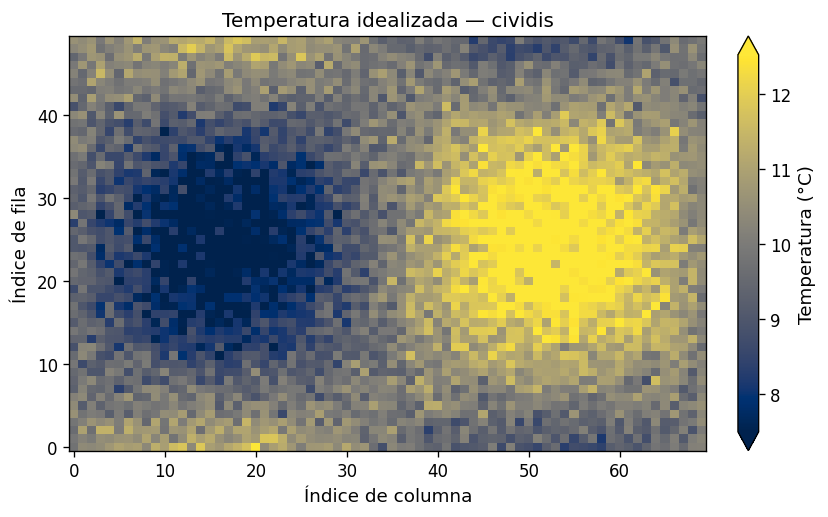

In [28]:
# 6.5 Mismo campo y misma escala para comparar dos mapas de color.
# Un generador propio permite repetir esta celda sin cambiar el resultado.
rng_campo = np.random.default_rng(52)
ny_campo, nx_campo = 50, 70
x_campo = np.linspace(-3, 3, nx_campo)
y_campo = np.linspace(-2, 2, ny_campo)
X_campo, Y_campo = np.meshgrid(x_campo, y_campo)
campo = 10 + 3 * np.sin(X_campo) * np.cos(Y_campo)
campo += rng_campo.normal(0, 0.5, size=campo.shape)
vmin_campo, vmax_campo = np.percentile(campo, [5, 95])

# Cada iteración crea una figura distinta, manteniendo todos los datos constantes.
for nombre_cmap in ("viridis", "cividis"):
    fig, ax = plt.subplots(figsize=(6.8, 4.2), layout="constrained")
    im = ax.imshow(
        campo, origin="lower", aspect="auto", interpolation="none",
        cmap=nombre_cmap, vmin=vmin_campo, vmax=vmax_campo,
    )
    ax.set_title(f"Temperatura idealizada — {nombre_cmap}")
    # Sin extent, las coordenadas visibles son índices, no longitudes y latitudes.
    ax.set_xlabel("Índice de columna")
    ax.set_ylabel("Índice de fila")
    fig.colorbar(im, ax=ax, label="Temperatura (°C)", extend="both")
    plt.show()

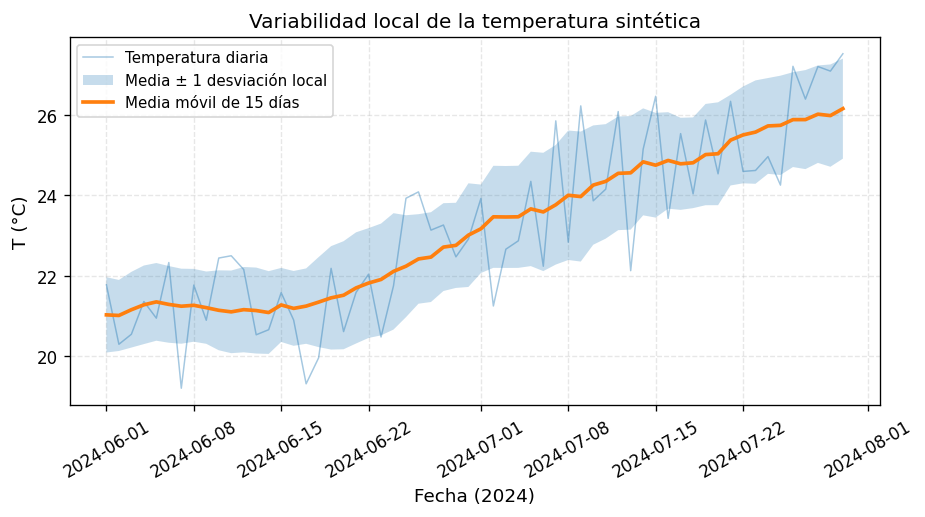

In [29]:
def desv_movil(x, w: int = 7) -> np.ndarray:
    """Desviación estándar local con las mismas ventanas que media_movil.

    Divide por el número de datos válidos de cada ventana (ddof=0).
    Describe dispersión de los datos, no incertidumbre de la media.
    """
    x = np.asarray(x, dtype=float)
    media = media_movil(x, w)  # También valida la serie y la ventana.
    resultado = np.full(media.shape, np.nan)
    mitad = w // 2
    for i in range(x.size):
        # Se recorta la ventana a los límites reales del array, sin añadir ceros.
        ventana = x[max(0, i - mitad):min(x.size, i + mitad + 1)]
        validos = ventana[np.isfinite(ventana)]
        if validos.size:
            resultado[i] = np.std(validos, ddof=0)
    return resultado


# 6.6 Media y desviación calculadas sobre los mismos datos de cada ventana.
T_mm15 = media_movil(T, 15)
T_sd15 = desv_movil(T, 15)
fig, ax = plt.subplots(figsize=(7.6, 4.2), layout="constrained")
ax.plot(fechas, T, linewidth=0.9, alpha=0.4, label="Temperatura diaria")
ax.fill_between(
    fechas, T_mm15 - T_sd15, T_mm15 + T_sd15,
    alpha=0.25, label="Media ± 1 desviación local",
)
ax.plot(fechas, T_mm15, linewidth=2.2, label="Media móvil de 15 días")
ax.set_title("Variabilidad local de la temperatura sintética")
ax.set_xlabel("Fecha (2024)")
ax.set_ylabel("T (°C)")
ax.tick_params(axis="x", labelrotation=30)
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(loc="upper left")
plt.show()

## 7. Tipos de gráficos meteorológicos frecuentes

La elección del gráfico depende de la pregunta. No necesitamos la misma representación para seguir una evolución temporal, comparar dos variables o estudiar una distribución. Los ejemplos siguientes utilizan las mismas series para mostrar qué aporta cada opción.

| Representación | Pregunta que ayuda a responder | Función |
| --- | --- | --- |
| Serie temporal | ¿Cómo evoluciona la variable? | `ax.plot()` |
| Dispersión | ¿Cómo se relacionan dos variables en los pares disponibles? | `ax.scatter()` |
| Histograma | ¿Cómo se distribuyen los valores entre intervalos? | `ax.hist()` |
| Barras | ¿Cómo se comparan cantidades por categoría o periodo? | `ax.bar()` |
| Diagrama de cajas | ¿Cómo cambian la mediana y la dispersión entre grupos? | `ax.boxplot()` |
| Diagrama de violín | ¿Qué forma tiene la distribución estimada en cada grupo? | `ax.violinplot()` |

**Series temporales y dispersión**

Una línea conecta datos ordenados en el tiempo. Esa conexión facilita seguir la evolución, pero no implica que conozcamos los valores entre observaciones. Los marcadores permiten ver dónde están los datos. Para precipitación acumulada durante intervalos separados, unas barras suelen expresar mejor la naturaleza de la variable.

En un diagrama de dispersión, cada punto representa un par de valores. En nuestro caso, la temperatura se sitúa en el eje horizontal y la humedad relativa en el vertical. Ajustar una recta con `np.polyfit(T, HR, deg=1)` resume una relación lineal de la muestra. No describe necesariamente una tendencia temporal ni demuestra causalidad. Conviene dibujarla sobre temperaturas ordenadas, para evitar un trazado que vaya de un punto a otro sin orden.

**Histogramas y densidad**

`bins` define los intervalos del histograma. Puede ser un número, una secuencia de límites o una regla automática, como `"fd"`, basada en el rango intercuartílico y el tamaño de la muestra.

Por defecto, las alturas son recuentos. Con `density=True`, el **área total** de las barras vale uno, no la suma de sus alturas. La proporción de datos de un intervalo se obtiene multiplicando su altura por su anchura. Si el eje horizontal está en m·s⁻¹, la densidad se expresa en s·m⁻¹. Los percentiles 50 y 90 indican valores por debajo de los cuales queda aproximadamente el 50 % y el 90 % de la muestra.

**Barras y cobertura temporal**

Para obtener acumulados por mes, convertimos las fechas a `datetime64[M]` y sumamos la precipitación de cada grupo. Las posiciones categóricas se construyen con `np.arange()` y sus etiquetas se asignan con `ax.set_xticks(posiciones, labels=etiquetas)`.

<div style="padding: 0.8em 1em; margin: 0.8em 0 1.2em; border-left: 4px solid #B88632; background-color: rgba(184,134,50,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.45em 0;"><strong>Meses incompletos.</strong> La serie cubre junio completo y los primeros 30 días de julio de 2024. Por tanto, el segundo acumulado corresponde a <strong>30 de los 31 días</strong> del mes. Las etiquetas mostrarán la cobertura disponible. Un periodo sin datos no debe interpretarse como precipitación nula.</p>
</div>

**Cajas y violines**

En el diagrama de cajas, la caja abarca del primer al tercer cuartil y la línea interior marca la mediana. Con `whis=1.5`, los bigotes alcanzan los datos más alejados que siguen dentro de 1,5 rangos intercuartílicos desde los extremos de la caja. Los puntos exteriores se muestran aparte; no son necesariamente errores ni fenómenos extremos desde un punto de vista meteorológico. `showmeans=True` añade la media con un símbolo diferente.

El violín representa una estimación suavizada de la distribución de cada grupo. Su anchura relativa muestra dónde se concentra la densidad estimada, pero los violines del ejemplo no comparan directamente el número de datos entre meses. El tamaño muestral y el suavizado afectan a su forma. En ambos gráficos indicaremos qué líneas o símbolos representan la media y la mediana.

Estas distribuciones resumen los días disponibles de la simulación. No son climatologías mensuales.

<p style="font-size: 0.9em; margin: 1em 0 0.3em;"><a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html">Histogramas</a> · <a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.boxplot.html">Diagramas de cajas</a> · <a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.violinplot.html">Diagramas de violín</a></p>

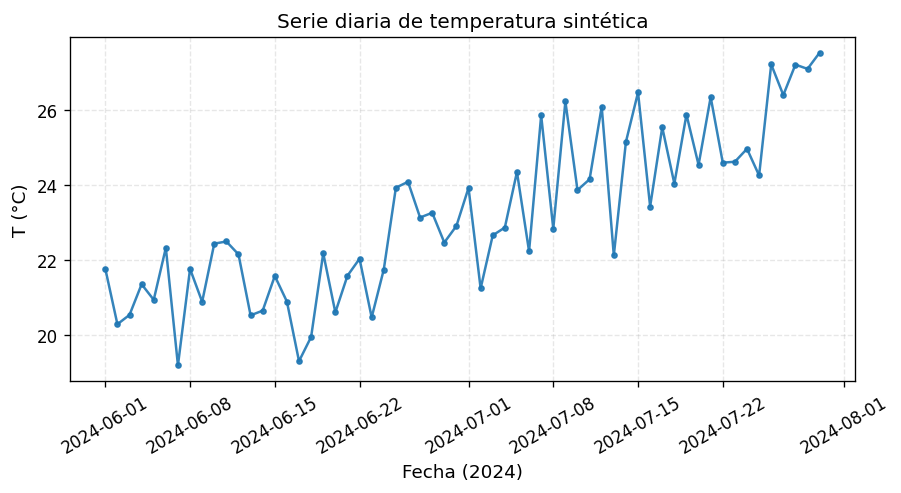

In [30]:
# 7.1 Los marcadores muestran las fechas con datos y la línea ayuda a seguir su evolución.
fig, ax = plt.subplots(figsize=(7.4, 4), layout="constrained")
ax.plot(fechas, T, linewidth=1.5, marker="o", markersize=3, alpha=0.9)
ax.set_title("Serie diaria de temperatura sintética")
ax.set_xlabel("Fecha (2024)")
ax.set_ylabel("T (°C)")
ax.tick_params(axis="x", labelrotation=30)
ax.grid(True, linestyle="--", alpha=0.3)
plt.show()

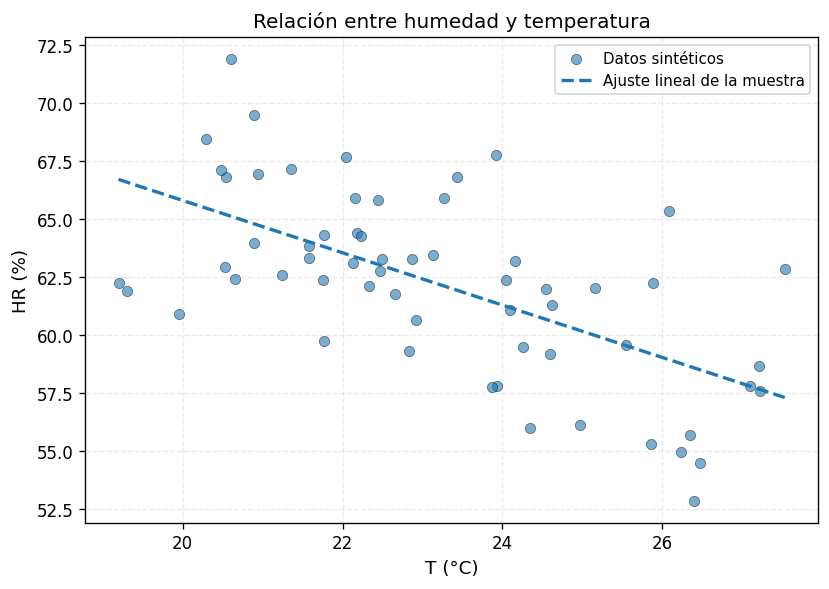

In [31]:
# 7.2 Cada punto representa un par de valores de la misma fecha.
fig, ax = plt.subplots(figsize=(6.8, 4.8), layout="constrained")
ax.scatter(T, HR, s=38, alpha=0.6, edgecolors="black", linewidths=0.4, label="Datos sintéticos")

# El ajuste devuelve la pendiente y la ordenada de HR = pendiente * T + intercepto.
pendiente, intercepto = np.polyfit(T, HR, deg=1)
T_linea = np.linspace(T.min(), T.max(), 100)
HR_ajuste = pendiente * T_linea + intercepto
ax.plot(T_linea, HR_ajuste, linewidth=2, linestyle="--", label="Ajuste lineal de la muestra")
ax.set_title("Relación entre humedad y temperatura")
ax.set_xlabel("T (°C)")
ax.set_ylabel("HR (%)")
ax.grid(True, linestyle="--", alpha=0.25)
ax.legend(loc="best")
plt.show()

Área total del histograma — 1.000


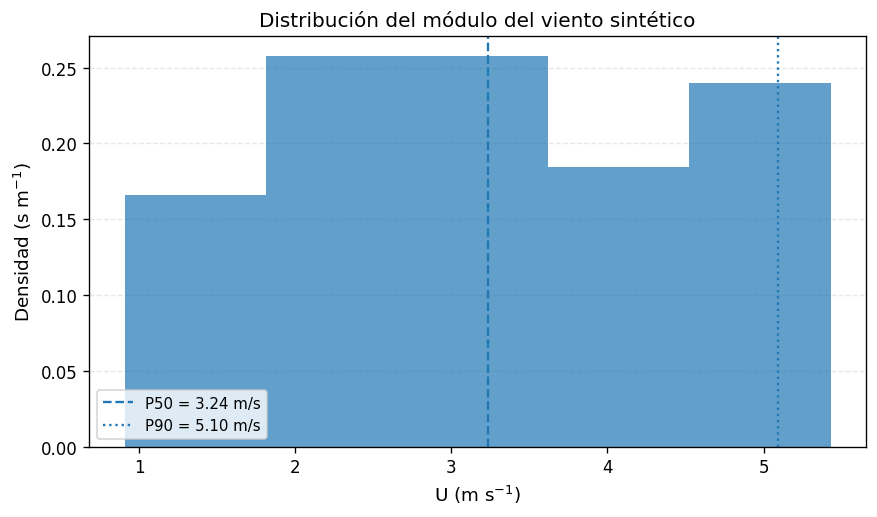

In [32]:
# 7.3 Un histograma normalizado por el área, no por la altura total.
fig, ax = plt.subplots(figsize=(7.2, 4.2), layout="constrained")
densidad, bordes, barras_hist = ax.hist(
    U, bins="fd", density=True,
    histtype="stepfilled", linewidth=0.8, alpha=0.7,
)
ax.set_title("Distribución del módulo del viento sintético")
ax.set_xlabel(r"U (m s$^{-1}$)")
ax.set_ylabel(r"Densidad (s m$^{-1}$)")
ax.grid(True, axis="y", linestyle="--", alpha=0.3)

p50, p90 = np.percentile(U, [50, 90])
ax.axvline(p50, linestyle="--", linewidth=1.4, label=f"P50 = {p50:.2f} m/s")
ax.axvline(p90, linestyle=":", linewidth=1.4, label=f"P90 = {p90:.2f} m/s")
ax.legend(loc="best")

# Altura multiplicada por anchura y sumada sobre las barras da el área total.
area_histograma = np.sum(densidad * np.diff(bordes))
print(f"Área total del histograma — {area_histograma:.3f}")
plt.show()

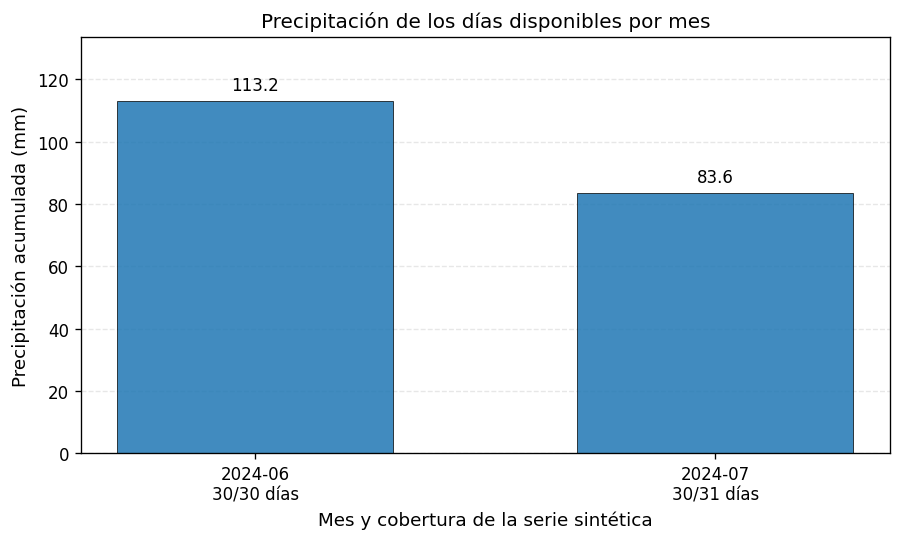

In [33]:
# 7.4 Agrupación por año y mes, conservando la información de cobertura.
meses = fechas.astype("datetime64[M]")
meses_unicos = np.unique(meses)
P_mensual = np.array([P[meses == mes].sum() for mes in meses_unicos])
dias_disponibles = np.array([(meses == mes).sum() for mes in meses_unicos])

# La diferencia entre inicios de meses consecutivos da su duración real.
inicios_mes = meses_unicos.astype("datetime64[D]")
inicios_siguiente = (meses_unicos + np.timedelta64(1, "M")).astype("datetime64[D]")
dias_mes = (inicios_siguiente - inicios_mes).astype(int)
nombres_mes = [np.datetime_as_string(mes, unit="M") for mes in meses_unicos]
etiquetas_mes = [
    f"{nombre}\n{disponibles}/{total} días"
    for nombre, disponibles, total in zip(nombres_mes, dias_disponibles, dias_mes)
]
xpos = np.arange(meses_unicos.size)

fig, ax = plt.subplots(figsize=(7.4, 4.4), layout="constrained")
barras = ax.bar(xpos, P_mensual, width=0.6, alpha=0.85, edgecolor="black", linewidth=0.5)
ax.set_title("Precipitación de los días disponibles por mes")
ax.set_xlabel("Mes y cobertura de la serie sintética")
ax.set_ylabel("Precipitación acumulada (mm)")
ax.set_xticks(xpos, labels=etiquetas_mes)
ax.set_ylim(0, P_mensual.max() * 1.18)
ax.grid(True, axis="y", linestyle="--", alpha=0.3)

for rect in barras:
    altura = rect.get_height()
    ax.annotate(
        f"{altura:.1f}",
        xy=(rect.get_x() + rect.get_width() / 2, altura),
        xytext=(0, 4), textcoords="offset points", ha="center", va="bottom",
    )
plt.show()

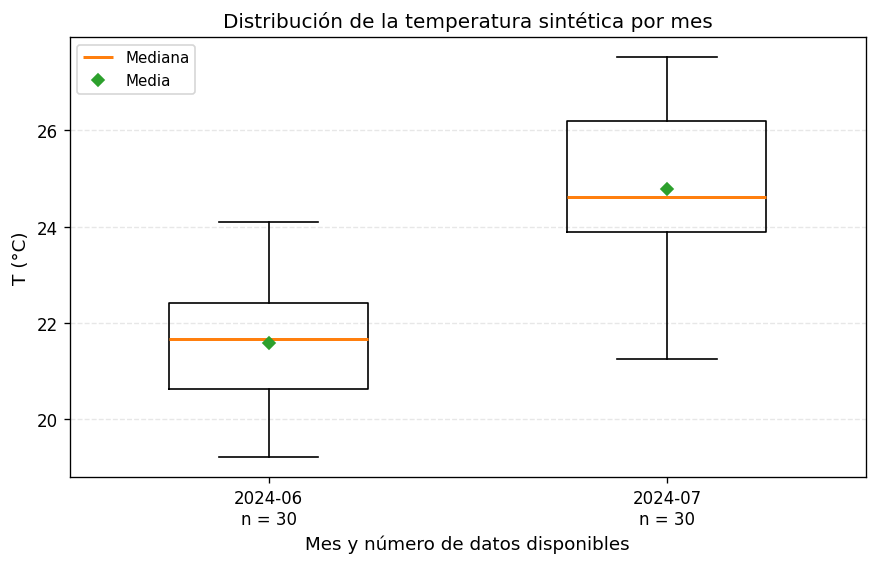

In [34]:
# 7.5 Cada grupo contiene los valores diarios disponibles de un mes.
meses = fechas.astype("datetime64[M]")
meses_unicos = np.unique(meses)
grupos_T = [T[meses == mes] for mes in meses_unicos]
etiquetas_cajas = [
    f"{mes}\nn = {grupo.size}" for mes, grupo in zip(meses_unicos, grupos_T)
]
fig, ax = plt.subplots(figsize=(7.2, 4.6), layout="constrained")
bp = ax.boxplot(
    grupos_T, tick_labels=etiquetas_cajas, showmeans=True, whis=1.5,
    widths=0.5, patch_artist=False,
    medianprops={"linewidth": 1.8},
    meanprops={"marker": "D", "markersize": 5, "linestyle": "none"},
)
ax.set_title("Distribución de la temperatura sintética por mes")
ax.set_xlabel("Mes y número de datos disponibles")
ax.set_ylabel("T (°C)")
ax.grid(True, axis="y", linestyle="--", alpha=0.3)
ax.legend([bp["medians"][0], bp["means"][0]], ["Mediana", "Media"], loc="upper left")
plt.show()

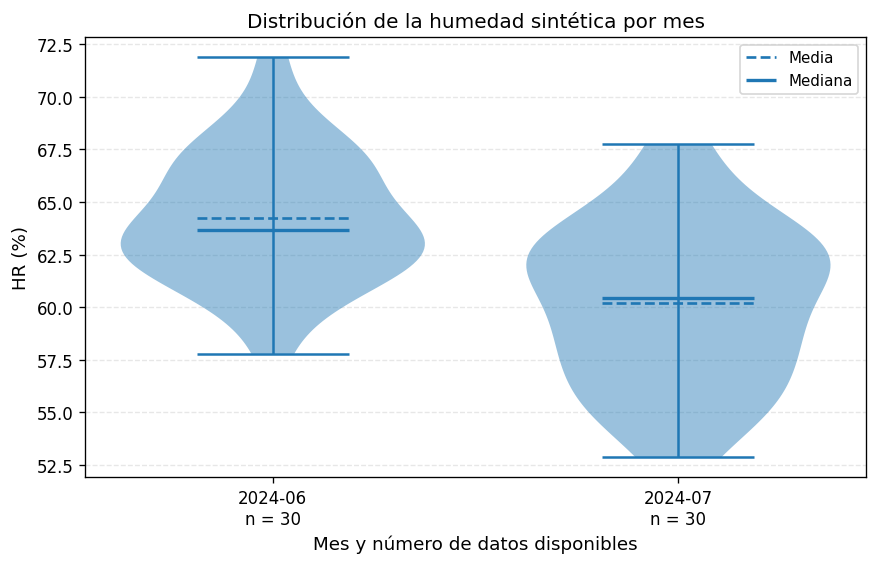

In [35]:
# 7.6 El ancho de cada violín representa la densidad estimada dentro del grupo.
meses = fechas.astype("datetime64[M]")
meses_unicos = np.unique(meses)
grupos_HR = [HR[meses == mes] for mes in meses_unicos]
etiquetas_violin = [
    f"{mes}\nn = {grupo.size}" for mes, grupo in zip(meses_unicos, grupos_HR)
]
fig, ax = plt.subplots(figsize=(7.2, 4.6), layout="constrained")
parts = ax.violinplot(
    grupos_HR, showmeans=True, showmedians=True, showextrema=True, widths=0.75,
)
for body in parts["bodies"]:
    body.set_alpha(0.45)
# Distinguimos los estadísticos también mediante el patrón de línea.
parts["cmeans"].set_linestyle("--")
parts["cmeans"].set_linewidth(1.6)
parts["cmedians"].set_linestyle("-")
parts["cmedians"].set_linewidth(2)
ax.set_xticks(np.arange(1, len(grupos_HR) + 1), labels=etiquetas_violin)
ax.set_title("Distribución de la humedad sintética por mes")
ax.set_xlabel("Mes y número de datos disponibles")
ax.set_ylabel("HR (%)")
ax.grid(True, axis="y", linestyle="--", alpha=0.3)
ax.legend([parts["cmeans"], parts["cmedians"]], ["Media", "Mediana"], loc="upper right")
plt.show()

## 8. Mapas simples y campos bidimensionales

Un **campo bidimensional** asigna un valor a cada posición de una rejilla. Puede representar temperatura a 850 hPa, precipitación o presión, entre otras magnitudes. En un array con forma `(ny, nx)`, el primer índice recorre las filas y el segundo las columnas. En los ejemplos, las filas siguen la latitud y las columnas la longitud.

<div style="padding: 0.8em 1em; margin: 0.8em 0 1.2em; border-left: 4px solid #4C78A8; background-color: rgba(76,120,168,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.45em 0;"><code>imshow()</code> dibuja el array como una imagen. <code>pcolormesh()</code> colorea celdas definidas por coordenadas. <code>contour()</code> traza líneas de igual valor y <code>contourf()</code> rellena las regiones comprendidas entre niveles. La <strong>barra de color</strong> relaciona esos colores con la magnitud representada.</p>
</div>

**Imágenes y posición de las celdas**

`imshow()` resulta apropiado para una rejilla rectangular con espaciado uniforme. `origin="lower"` sitúa la primera fila en la parte inferior. Con `interpolation="none"` evitamos introducir un suavizado visual de la imagen.

El argumento `extent=[izquierda, derecha, abajo, arriba]` especifica los **bordes exteriores de la imagen**, no las coordenadas de los centros de sus píxeles. Como nuestras longitudes y latitudes representan centros de celdas, extendemos el dominio medio paso por cada lado. Así los píxeles coinciden con las coordenadas utilizadas al superponer contornos.

```python
paso_lon = lons[1] - lons[0]
paso_lat = lats[1] - lats[0]
extent = [
    lons[0] - paso_lon / 2, lons[-1] + paso_lon / 2,
    lats[0] - paso_lat / 2, lats[-1] + paso_lat / 2,
]
```

**Mallas y coordenadas**

`pcolormesh()` admite rejillas con espaciado no uniforme y coordenadas bidimensionales. Si las matrices de coordenadas tienen la misma forma que el campo, `shading="auto"` interpreta sus posiciones como centros y selecciona el modo correspondiente. Si describen los vértices, deben tener una fila y una columna adicionales. Este argumento elige entre convenciones válidas, pero no corrige unas coordenadas mal construidas.

**Contornos y escala de color**

`contour()` y `contourf()` utilizan `levels` para definir los valores de las isolíneas y los límites de las bandas. `ax.clabel()` añade etiquetas sobre las líneas. Los contornos interpolan posiciones entre puntos de la rejilla, por lo que no aportan observaciones nuevas.

Mantendremos la misma paleta y los mismos límites al comparar métodos sobre `T850`. La escala se acota a los percentiles 5 y 95 y las extensiones de las barras señalarán los valores exteriores. Cambiar esos límites de una figura a otra dificultaría comparar colores.

`fig.colorbar(im, ax=ax)` vincula la barra al objeto que contiene el campo coloreado. La etiqueta debe identificar la magnitud y la unidad. `orientation="horizontal"` permite situarla horizontalmente, mientras que `pad`, `fraction` y `aspect` controlan separación y proporciones.

**Longitud y latitud no son distancias cartesianas**

En una aproximación esférica, un grado de longitud abarca una distancia proporcional a $\cos\varphi$, donde $\varphi$ es la latitud. Aplicaremos una relación de aspecto $1/\cos\varphi_0$, calculada en la latitud media del dominio, para mejorar la proporción visual local.

<div style="padding: 0.8em 1em; margin: 0.8em 0 1.2em; border-left: 4px solid #B88632; background-color: rgba(184,134,50,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.45em 0;"><strong>Alcance del dibujo.</strong> Ajustar la relación de aspecto no equivale a aplicar una proyección cartográfica. Estos ejemplos muestran un campo idealizado en coordenadas geográficas, sin costas ni transformaciones de proyección. La aproximación de aspecto no debe extrapolarse a dominios grandes o polares.</p>
</div>

**Datos ausentes y máscaras**

Un array enmascarado conserva los datos y añade una máscara booleana que indica qué posiciones deben omitirse. No convierte esos valores en «NaN lógicos». También es posible representar ausencias mediante `NaN` en arrays de coma flotante.

El último ejemplo oculta una zona rectangular elegida por sus coordenadas para simular falta de datos, sin seleccionar las temperaturas más bajas ni modificar `T850`. Una copia del mapa de color permite asignar un color específico a las celdas ausentes mediante `set_bad()`. Ese color se identificará en la leyenda, porque no pertenece a la escala numérica de temperatura.

<p style="font-size: 0.9em; margin: 1em 0 0.3em;"><a href="https://matplotlib.org/stable/users/explain/artists/imshow_extent.html">Posición de las imágenes</a> · <a href="https://matplotlib.org/stable/gallery/images_contours_and_fields/pcolormesh_grids.html">Mallas y sombreado</a></p>

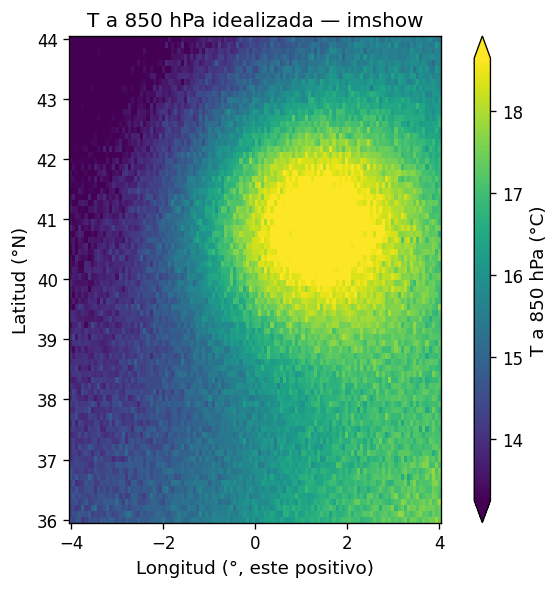

In [36]:
# 8.0 Coordenadas de los centros de celda y campo idealizado a 850 hPa.
rng_mapa = np.random.default_rng(42)
lats = np.linspace(36.0, 44.0, 80)
lons = np.linspace(-4.0, 4.0, 120)
Lon, Lat = np.meshgrid(lons, lats)  # Ambas matrices tienen forma (80, 120).

T850 = (
    15.0
    + 4.0 * np.exp(-((Lat - 41.0) ** 2 / 2.0**2 + (Lon - 1.0) ** 2 / 2.5**2))
    + 1.5 * np.sin(np.deg2rad(Lon * 20))
    - 0.25 * (Lat - 40.0)
    + rng_mapa.normal(0, 0.2, size=Lon.shape)
)
vmin_mapa, vmax_mapa = np.percentile(T850, [5, 95])

# extent debe describir los bordes exteriores, medio paso más allá de los centros.
paso_lon = lons[1] - lons[0]
paso_lat = lats[1] - lats[0]
extent = [
    lons[0] - paso_lon / 2, lons[-1] + paso_lon / 2,
    lats[0] - paso_lat / 2, lats[-1] + paso_lat / 2,
]
lat0 = lats.mean()
aspect_geo = 1 / np.cos(np.deg2rad(lat0))  # Aproximación local, no proyección.

# 8.1 La primera fila representa el sur y se dibuja en la parte inferior.
fig, ax = plt.subplots(figsize=(7.2, 4.8), layout="constrained")
im = ax.imshow(
    T850, origin="lower", extent=extent, interpolation="none",
    cmap="viridis", vmin=vmin_mapa, vmax=vmax_mapa,
)
ax.set_title("T a 850 hPa idealizada — imshow")
ax.set_xlabel("Longitud (°, este positivo)")
ax.set_ylabel("Latitud (°N)")
ax.set_aspect(aspect_geo)
fig.colorbar(
    im, ax=ax, label="T a 850 hPa (°C)", extend="both",
    orientation="vertical", fraction=0.05, pad=0.04, aspect=30,
)
plt.show()

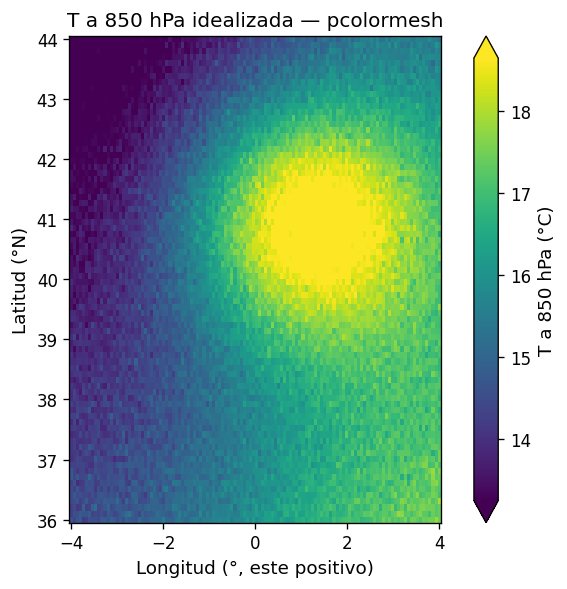

In [37]:
# 8.2 Lon y Lat tienen la misma forma que T850 y representan centros de celda.
fig, ax = plt.subplots(figsize=(7.2, 4.8), layout="constrained")
pc = ax.pcolormesh(
    Lon, Lat, T850, shading="auto", antialiased=False,
    cmap="viridis", vmin=vmin_mapa, vmax=vmax_mapa,
)
ax.set_title("T a 850 hPa idealizada — pcolormesh")
ax.set_xlabel("Longitud (°, este positivo)")
ax.set_ylabel("Latitud (°N)")
ax.set_aspect(aspect_geo)
ax.set_xlim(extent[0], extent[1])
ax.set_ylim(extent[2], extent[3])
fig.colorbar(pc, ax=ax, label="T a 850 hPa (°C)", extend="both", fraction=0.05, pad=0.04)
plt.show()

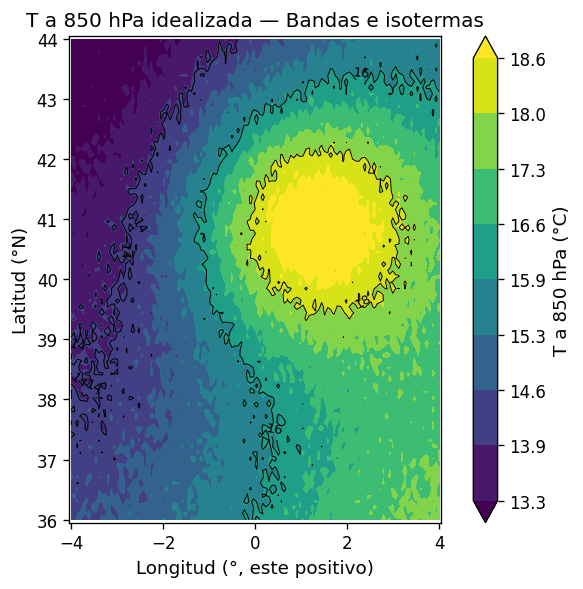

In [38]:
# 8.3 Los niveles del relleno cubren el mismo rango que la escala continua anterior.
niveles = np.linspace(vmin_mapa, vmax_mapa, 9)
niveles_lineas = np.arange(np.ceil(vmin_mapa), np.floor(vmax_mapa) + 1, 2)
fig, ax = plt.subplots(figsize=(7.2, 4.8), layout="constrained")
cf = ax.contourf(
    Lon, Lat, T850, levels=niveles, cmap="viridis",
    vmin=vmin_mapa, vmax=vmax_mapa, extend="both",
)
cs = ax.contour(Lon, Lat, T850, levels=niveles_lineas, colors="k", linewidths=0.6)
ax.clabel(cs, fmt="%.0f", inline=True, fontsize=8)
ax.set_title("T a 850 hPa idealizada — Bandas e isotermas")
ax.set_xlabel("Longitud (°, este positivo)")
ax.set_ylabel("Latitud (°N)")
ax.set_aspect(aspect_geo)
ax.set_xlim(extent[0], extent[1])
ax.set_ylim(extent[2], extent[3])
fig.colorbar(cf, ax=ax, label="T a 850 hPa (°C)", fraction=0.05, pad=0.04, format="%.1f")
plt.show()

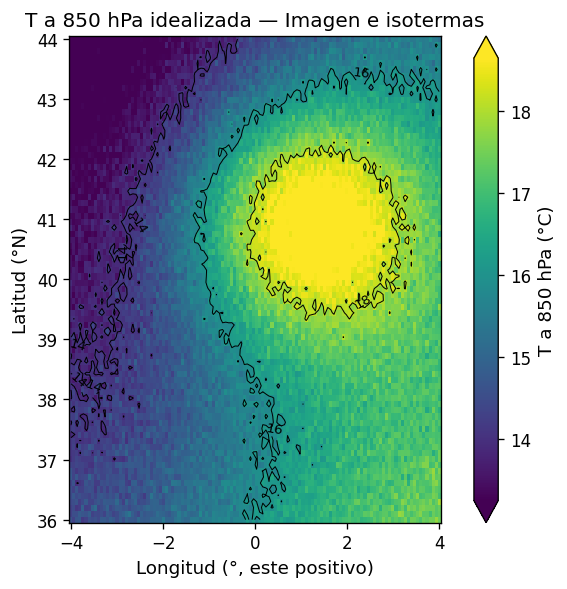

In [39]:
# 8.4 Imagen y contornos usan exactamente las mismas coordenadas de centro.
niveles_lineas = np.arange(np.ceil(vmin_mapa), np.floor(vmax_mapa) + 1, 2)
fig, ax = plt.subplots(figsize=(7.2, 4.8), layout="constrained")
im = ax.imshow(
    T850, origin="lower", extent=extent, interpolation="none",
    cmap="viridis", vmin=vmin_mapa, vmax=vmax_mapa,
)
cs = ax.contour(Lon, Lat, T850, levels=niveles_lineas, colors="k", linewidths=0.6)
ax.clabel(cs, fmt="%.0f", inline=True, fontsize=8)
ax.set_title("T a 850 hPa idealizada — Imagen e isotermas")
ax.set_xlabel("Longitud (°, este positivo)")
ax.set_ylabel("Latitud (°N)")
ax.set_aspect(aspect_geo)
ax.set_xlim(extent[0], extent[1])
ax.set_ylim(extent[2], extent[3])
fig.colorbar(im, ax=ax, label="T a 850 hPa (°C)", extend="both", fraction=0.05, pad=0.04)
plt.show()

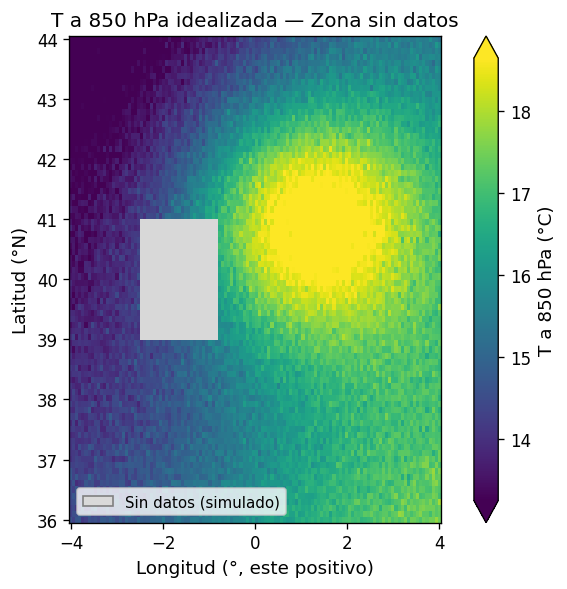

In [40]:
from matplotlib.patches import Patch

# 8.5 Ausencia de datos simulada mediante una región, no mediante sus temperaturas.
mascara = (Lon >= -2.5) & (Lon <= -0.8) & (Lat >= 39.0) & (Lat <= 41.0)
T_mask = np.ma.masked_where(mascara, T850, copy=True)
cmap_mascara = plt.colormaps["viridis"].copy()
cmap_mascara.set_bad("0.85")

fig, ax = plt.subplots(figsize=(7.2, 4.8), layout="constrained")
im = ax.imshow(
    T_mask, origin="lower", extent=extent, interpolation="none",
    cmap=cmap_mascara, vmin=vmin_mapa, vmax=vmax_mapa,
)
ax.set_title("T a 850 hPa idealizada — Zona sin datos")
ax.set_xlabel("Longitud (°, este positivo)")
ax.set_ylabel("Latitud (°N)")
ax.set_aspect(aspect_geo)
fig.colorbar(im, ax=ax, label="T a 850 hPa (°C)", extend="both", fraction=0.05, pad=0.04)

# El color de ausencia no pertenece a la escala de temperatura y se identifica aparte.
referencia_ausencia = Patch(facecolor=cmap_mascara.get_bad(), edgecolor="0.5", label="Sin datos (simulado)")
ax.legend(handles=[referencia_ausencia], loc="lower left")
plt.show()

# Ejercicios

<div style="height: 4px; background-color: #4C78A8; border-radius: 2px; margin: 0.8em 0 1.2em;"></div>

## 1. Serie temporal con banda de variabilidad y anotaciones

La celda siguiente genera una temperatura diaria sintética para 2024. Los nombres `fechas_ex1` y `T_ex1` identifican las fechas y los valores de este ejercicio, sin sustituir las series de los ejemplos anteriores.

1. Representa `T_ex1` en función de `fechas_ex1`, indicando la magnitud, las unidades y el carácter sintético de los datos.
2. Calcula una media móvil centrada de 7 días y su desviación estándar móvil. Puedes reutilizar `media_movil()` y `desv_movil()`. Sombrea el intervalo de media ± una desviación con `fill_between()` y explica qué representa la banda.
3. Añade una línea horizontal en un umbral ilustrativo, por ejemplo 30 °C, sin presentarlo como criterio de ola de calor.
4. Anota el máximo y el mínimo de la serie original mediante `annotate()`, con flecha y recuadro. Comprueba que el texto no tape los datos ni salga de la figura.
5. Exporta la figura a PNG con `dpi=300`, utilizando un nombre propio para el ejercicio.

<div style="padding: 0.8em 1em; margin: 0.8em 0 1.2em; border-left: 4px solid #59A14F; background-color: rgba(89,161,79,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.45em 0;"><strong>Interpretación.</strong> La banda describe variabilidad entre días cercanos. No representa la incertidumbre de la media. En los extremos del año, las funciones utilizan los datos disponibles y la ventana contiene menos de siete valores.</p>
</div>

In [41]:
import numpy as np
import pandas as pd

# Datos del ejercicio 1. La semilla no altera los demás generadores del notebook.
rng_ex1 = np.random.default_rng(34)
fechas_ex1 = pd.date_range("2024-01-01", "2024-12-31", freq="D")
T_ex1 = 20 + rng_ex1.normal(0, 3, size=fechas_ex1.size)
# Esta simulación sencilla no incorpora un ciclo estacional realista.

## 2. Multipanel con ejes compartidos e intervalo lluvioso

La celda siguiente prepara `fechas_ex2`, `T_ex2` y `P_ex2`. La precipitación se expresa como cantidad acumulada durante cada día, en mm, y contiene un intervalo lluvioso incorporado a la simulación.

1. Crea una figura de dos filas y una columna con `sharex=True`. Representa `T_ex2` arriba y `P_ex2` con barras abajo. Mantén separados los ejes verticales y sus unidades.
2. Localiza la **ventana de cinco días consecutivos con mayor precipitación acumulada**, considerando solo ventanas completas. Sombrea ese mismo intervalo en los dos paneles con `axvspan()` e indica su acumulado. Si hubiera un empate, utiliza la primera ventana.
3. Añade un título global con `fig.suptitle()`, títulos de panel y fechas legibles. Ajusta los márgenes con un único enfoque, ya sea `layout="constrained"` o un ajuste manual.

<div style="padding: 0.8em 1em; margin: 0.8em 0 1.2em; border-left: 4px solid #59A14F; background-color: rgba(89,161,79,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.45em 0;"><strong>Delimitar la pregunta.</strong> Fijamos la duración para comparar ventanas equivalentes. Puedes repetir la búsqueda con tres o cuatro días y observar cómo cambia el resultado. La ventana más lluviosa no tiene por qué coincidir con un episodio completo ni contener lluvia en todos sus días.</p>
</div>

In [42]:
import numpy as np
import pandas as pd

# Datos propios del ejercicio 2, independientes de las variables del ejercicio 1.
rng_ex2 = np.random.default_rng(34)
fechas_ex2 = pd.date_range("2024-01-01", "2024-12-31", freq="D")
T_ex2 = 20 + rng_ex2.normal(0, 3, size=fechas_ex2.size)

# P_ex2 contiene cantidades diarias en mm, no intensidades instantáneas.
P_ex2 = np.zeros(fechas_ex2.size)
dias_humedos = rng_ex2.random(fechas_ex2.size) < 0.25
P_ex2[dias_humedos] = rng_ex2.exponential(scale=5, size=dias_humedos.sum())

# Incorporamos cinco días con más lluvia a esta simulación, sin resolver la búsqueda.
intervalo_simulado = (fechas_ex2 >= "2024-10-05") & (fechas_ex2 <= "2024-10-09")
P_ex2[intervalo_simulado] += 20 + rng_ex2.exponential(scale=20, size=intervalo_simulado.sum())

## 3. Dispersión de humedad y temperatura con ajuste lineal y correlación

Los arrays `T_ex3` y `HR_ex3` contienen 400 pares sintéticos. La relación decreciente se ha incorporado deliberadamente al generarlos y se ha añadido variabilidad aleatoria.

1. Representa la temperatura en el eje horizontal y la humedad relativa en el vertical mediante `ax.scatter()`. Ajusta `s` y `alpha` para que los puntos superpuestos sigan siendo distinguibles.
2. Ajusta una recta con `np.polyfit()` y dibújala con línea discontinua sobre una secuencia ordenada de temperaturas dentro del rango observado.
3. Calcula el coeficiente de correlación de Pearson `r` con `np.corrcoef(T_ex3, HR_ex3)[0, 1]` y anótalo en la figura con dos decimales. Describe su signo y recuerda que resume una asociación lineal de la muestra, no una relación causal.

In [43]:
import numpy as np

# Datos propios del ejercicio 3. Cada posición contiene un par temperatura–humedad.
rng_ex3 = np.random.default_rng(34)
n_pares = 400
T_ex3 = rng_ex3.normal(loc=22, scale=6, size=n_pares)
T_ex3 = np.clip(T_ex3, -5, 45)  # Límites elegidos para el ejemplo, no universales.
HR_ex3 = 75 - 1.3 * T_ex3 + rng_ex3.normal(loc=0, scale=8, size=n_pares)
HR_ex3 = np.clip(HR_ex3, 1, 100)  # Recorte propio de la generación de datos sintéticos.